# Projeto Final: Experiência do Cliente na Olist

**Autora:** Luciana Jost

**Bootcamp de Análise de Dados - TripleTen**

**Data:** outubro de 2026

**Arquivos do projeto (Google Drive):** https://drive.google.com/drive/folders/1YknyHFHUdyHX_TCUnA9ShqqZyVMuLUpS

**Dashboard (Tableau Public):** https://public.tableau.com/views/OlistExperinciadoclienteeavaliaonegativa/PainelOlist

## 1. Introdução

Este notebook executa a análise planejada na decomposição do Caso Principal, aprovada pelo líder de equipe.

**Pergunta do projeto:** quais fatores da jornada de compra reduzem a satisfação do cliente da Olist, e qual deles tem maior peso?

**Base de dados:** Brazilian E-Commerce Public Dataset by Olist (Kaggle), com cerca de 100 mil pedidos realizados entre 2016 e 2018. As conclusões se referem ao modelo de operação desse período, e não necessariamente à atuação atual da empresa.

**Hipóteses:**

- **H1:** entre pedidos com tempo de entrega semelhante, os que chegam depois da data estimada recebem notas menores.
- **H2:** entre os pedidos entregues fora do prazo, as notas são menores quando o cliente responde à pesquisa antes de receber o produto.
- **H3:** cada dia de atraso reduz a nota mais do que cada dia de antecipação a aumenta.
- **H4:** nas entregas dentro do prazo, a insatisfação se relaciona mais ao produto do que nas entregas fora do prazo.

**Indicador principal:** taxa de avaliação negativa, definida como a proporção de pedidos com nota 1 ou 2.

> **Nota sobre a execução:** este notebook foi executado integralmente, do início ao fim, no ambiente Jupyter da plataforma TripleTen. Todos os arquivos necessários estão no próprio ambiente, organizados desta forma:
>
> ```
> (pasta do notebook)/
> ├── projeto_final.ipynb
> ├── validacao_h4_amostra.csv      (classificação manual usada na seção 4.4)
> └── dados/                        (7 tabelas da Olist, em CSV compactado)
> ```
>
> As tabelas estão compactadas no formato `.csv.gz` para caber nos limites de tamanho da plataforma. O pandas lê esse formato diretamente, sem descompactar. As versões das bibliotecas utilizadas estão listadas na seção 1.1.

### Estrutura da análise

1. Introdução
2. Preparação dos dados
3. Análise exploratória
4. Teste das hipóteses
5. Conclusões e recomendações
6. Entregáveis e fontes

### 1.1 Ambiente e dependências

Para garantir a reprodutibilidade, a célula abaixo registra as versões do Python e das bibliotecas utilizadas na execução deste notebook. Além delas, a análise usa apenas módulos da biblioteca padrão do Python (`math`, `unicodedata` e `pathlib`).

| Biblioteca | Uso no projeto |
|---|---|
| pandas | leitura, preparação e agregação dos dados |
| matplotlib | gráficos e modelo de associações |
| scipy | testes estatísticos (teste z, Mann-Whitney, Fisher, regressão linear) |


In [1]:
import sys

import matplotlib
import pandas
import scipy

print('Python:', sys.version.split()[0])
print('pandas:', pandas.__version__)
print('matplotlib:', matplotlib.__version__)
print('scipy:', scipy.__version__)

Python: 3.13.16
pandas: 3.0.5
matplotlib: 3.11.2
scipy: 1.18.1


## 2. Preparação dos dados

### 2.1 Carregamento

A análise utiliza sete das nove tabelas da base, as mesmas descritas na decomposição. As tabelas são lidas da pasta `dados/`, em formato CSV compactado (`.csv.gz`).


In [2]:
import math
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from scipy import stats as st

PASTA = '../dados/'

orders = pd.read_csv(PASTA + 'olist_orders_dataset.csv.gz')
reviews = pd.read_csv(PASTA + 'olist_order_reviews_dataset.csv.gz')
items = pd.read_csv(PASTA + 'olist_order_items_dataset.csv.gz')
products = pd.read_csv(PASTA + 'olist_products_dataset.csv.gz')
sellers = pd.read_csv(PASTA + 'olist_sellers_dataset.csv.gz')
customers = pd.read_csv(PASTA + 'olist_customers_dataset.csv.gz')
categories = pd.read_csv(PASTA + 'product_category_name_translation.csv.gz')

tabelas = {
    'orders': orders,
    'reviews': reviews,
    'items': items,
    'products': products,
    'sellers': sellers,
    'customers': customers,
    'categories': categories
}

pd.DataFrame(
    [(nome, df.shape[0], df.shape[1]) for nome, df in tabelas.items()],
    columns=['tabela', 'linhas', 'colunas']
)

,tabela,linhas,colunas
0,orders,99441,8
1,reviews,99224,7
2,items,112650,7
3,products,32951,9
4,sellers,3095,4
5,customers,99441,5
6,categories,71,2


As sete tabelas foram carregadas com os mesmos volumes descritos na decomposição: 99.441 pedidos, 99.224 avaliações e 112.650 itens.

A preparação a seguir executa as nove ações previstas na seção 5.1 da decomposição.

### 2.2 Conversão das datas

Na decomposição, as oito colunas de data da base foram identificadas como texto. A célula a seguir converte todas para o tipo `datetime` e confirma o resultado.

In [3]:
COLUNAS_DE_DATA = {
    'orders': [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
    ],
    'reviews': ['review_creation_date', 'review_answer_timestamp'],
    'items': ['shipping_limit_date'],
}

for nome, colunas in COLUNAS_DE_DATA.items():
    for coluna in colunas:
        tabelas[nome][coluna] = pd.to_datetime(tabelas[nome][coluna])

pd.DataFrame(
    [
        (nome, coluna, str(tabelas[nome][coluna].dtype))
        for nome, colunas in COLUNAS_DE_DATA.items()
        for coluna in colunas
    ],
    columns=['tabela', 'coluna', 'tipo'],
)

,tabela,coluna,tipo
0,orders,order_purchase_timestamp,datetime64[us]
1,orders,order_approved_at,datetime64[us]
2,orders,order_delivered_carrier_date,datetime64[us]
3,orders,order_delivered_customer_date,datetime64[us]
4,orders,order_estimated_delivery_date,datetime64[us]
5,reviews,review_creation_date,datetime64[us]
6,reviews,review_answer_timestamp,datetime64[us]
7,items,shipping_limit_date,datetime64[us]


As oito colunas de data foram convertidas para o tipo `datetime`, o que permite calcular intervalos de tempo entre as etapas do pedido.

### 2.3 Seleção dos pedidos entregues

A análise depende da comparação entre a data de entrega e a data prometida, por isso considera apenas os pedidos com status `delivered` e data de entrega registrada. Esse filtro também exclui os 14 pedidos com status e data inconsistentes identificados na decomposição.

In [4]:
pedidos = orders[
    (orders['order_status'] == 'delivered')
    & orders['order_delivered_customer_date'].notna()
].copy()

print('Pedidos na base:', len(orders))
print('Pedidos entregues com data de entrega:', len(pedidos))
print('Pedidos excluídos:', len(orders) - len(pedidos))

Pedidos na base: 99441
Pedidos entregues com data de entrega: 96470
Pedidos excluídos: 2971


Dos 99.441 pedidos, 96.470 foram entregues e têm data de entrega registrada. Os 2.971 pedidos excluídos correspondem aos pedidos que não chegaram ao cliente (cancelados, em trânsito, indisponíveis e outros status) e aos 8 pedidos com status `delivered` sem data de entrega.

### 2.4 Uma avaliação por pedido

Na decomposição, 547 pedidos apresentavam mais de uma avaliação. Para manter uma única nota por pedido, a célula a seguir mantém a avaliação respondida por último, que reflete a percepção final do cliente. Em seguida, une as avaliações aos pedidos entregues. Os pedidos sem avaliação são excluídos, pois não têm medida de satisfação.

In [5]:
avaliacoes = (
    reviews.sort_values('review_answer_timestamp')
    .drop_duplicates(subset='order_id', keep='last')
)

pedidos_avaliados = pedidos.merge(avaliacoes, on='order_id', how='inner')

print('Avaliações na base:', len(reviews))
print('Avaliações após manter uma por pedido:', len(avaliacoes))
print('Pedidos entregues e avaliados:', len(pedidos_avaliados))
print('Pedidos entregues sem avaliação (excluídos):', len(pedidos) - len(pedidos_avaliados))

Avaliações na base: 99224
Avaliações após manter uma por pedido: 98673
Pedidos entregues e avaliados: 95824
Pedidos entregues sem avaliação (excluídos): 646


- Das 99.224 avaliações, 98.673 permanecem após manter uma por pedido. Foram removidas 551 avaliações, número um pouco maior do que o de pedidos afetados (547), pois alguns pedidos tinham três avaliações.
- 95.824 pedidos entregues têm avaliação e formam a base da análise de satisfação.
- 646 pedidos entregues não têm avaliação e foram excluídos.

### 2.5 Agregação dos itens por pedido

A tabela `items` registra uma linha por item vendido, e a unidade de análise é o pedido. A célula a seguir resume os itens de cada pedido em uma única linha, com o número de itens, o número de vendedores distintos, o valor total dos produtos, o valor total do frete e a categoria principal. A categoria principal é a do primeiro item do pedido.

In [6]:
itens_com_categoria = items.merge(
    products[['product_id', 'product_category_name']], on='product_id', how='left'
)

resumo_itens = (
    itens_com_categoria.groupby('order_id')
    .agg(
        numero_de_itens=('order_item_id', 'count'),
        numero_de_vendedores=('seller_id', 'nunique'),
        valor_produtos=('price', 'sum'),
        valor_frete=('freight_value', 'sum'),
    )
    .reset_index()
)

categoria_principal = (
    itens_com_categoria.sort_values('order_item_id')
    .drop_duplicates(subset='order_id')
    [['order_id', 'product_category_name']]
)

resumo_itens = resumo_itens.merge(categoria_principal, on='order_id', how='left')

print('Pedidos com itens:', len(resumo_itens))
display(resumo_itens['numero_de_vendedores'].value_counts().sort_index().to_frame('pedidos'))
resumo_itens.head()

Pedidos com itens: 98666


,pedidos
numero_de_vendedores,
1,97388
2,1219
3,54
4,3
5,2


,order_id,numero_de_itens,numero_de_vendedores,valor_produtos,valor_frete,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,1,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,199.90,18.14,ferramentas_jardim


- 98.666 pedidos têm itens registrados. A diferença em relação aos 99.441 pedidos da base corresponde a pedidos sem itens, como cancelados ou indisponíveis, que já ficaram de fora da seleção da seção 2.3.
- 97.388 pedidos (98,7%) têm um único vendedor. Os 1.278 pedidos restantes (1,3%) envolvem dois a cinco vendedores e podem chegar ao cliente em entregas separadas. Esse grupo é examinado na análise complementar da H4.

### 2.6 Base única

A célula a seguir une os pedidos avaliados ao resumo dos itens e ao estado do cliente, formando uma base com uma linha por pedido. Em seguida, verifica se a união gerou pedidos repetidos ou informações ausentes.

In [7]:
base = (
    pedidos_avaliados
    .merge(resumo_itens, on='order_id', how='left')
    .merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
)

print('Linhas da base:', len(base))
print('Pedidos repetidos:', base['order_id'].duplicated().sum())
print('Pedidos sem itens:', base['numero_de_itens'].isna().sum())
print('Pedidos sem estado do cliente:', base['customer_state'].isna().sum())

Linhas da base: 95824
Pedidos repetidos: 0
Pedidos sem itens: 0
Pedidos sem estado do cliente: 0


A base tem 95.824 linhas, uma por pedido entregue e avaliado. A união não gerou pedidos repetidos, e todos os pedidos têm o resumo dos itens e o estado do cliente.

### 2.7 Variáveis derivadas

A célula a seguir cria as variáveis previstas na decomposição:

| Variável | Definição |
|---|---|
| `tempo_entrega_dias` | Dias entre a compra e a entrega ao cliente |
| `diferenca_prazo_dias` | Dias entre a data da entrega e a data estimada. Valores negativos indicam antecipação e positivos, atraso |
| `fora_do_prazo` | Verdadeiro quando a entrega ocorre em dia posterior à data estimada |
| `avaliacao_negativa` | Verdadeiro quando a nota é 1 ou 2 |
| `avaliacao_antes_da_entrega` | Verdadeiro quando o cliente respondeu à pesquisa antes de receber o produto |

A data estimada de entrega é registrada sem horário. Por isso, a diferença em relação ao prazo é calculada em dias inteiros, comparando a data da entrega com a data estimada: um pedido entregue no próprio dia estimado é considerado dentro do prazo.

A variável de tema do comentário, usada na H4, é criada na seção correspondente.

In [8]:
SEGUNDOS_POR_DIA = 86400

base['tempo_entrega_dias'] = (
    base['order_delivered_customer_date'] - base['order_purchase_timestamp']
).dt.total_seconds() / SEGUNDOS_POR_DIA

base['diferenca_prazo_dias'] = (
    base['order_delivered_customer_date'].dt.normalize()
    - base['order_estimated_delivery_date']
).dt.days

base['fora_do_prazo'] = base['diferenca_prazo_dias'] > 0
base['avaliacao_negativa'] = base['review_score'] <= 2
base['avaliacao_antes_da_entrega'] = (
    base['review_answer_timestamp'] < base['order_delivered_customer_date']
)

print(f"Pedidos fora do prazo: {base['fora_do_prazo'].sum()} ({base['fora_do_prazo'].mean():.1%})")
print(f"Avaliações negativas: {base['avaliacao_negativa'].sum()} ({base['avaliacao_negativa'].mean():.1%})")

base[['tempo_entrega_dias', 'diferenca_prazo_dias']].describe().round(2)

Pedidos fora do prazo: 6381 (6.7%)
Avaliações negativas: 12272 (12.8%)


,tempo_entrega_dias,diferenca_prazo_dias
count,95824.00,95824.00
mean,12.52,-11.91
std,9.46,10.11
min,0.53,-147.00
25%,6.76,-17.00
50%,10.21,-12.00
75%,15.66,-7.00
max,208.35,188.00


- **Tempo de entrega:** a mediana é de 10,2 dias, e metade dos pedidos chega entre 6,8 e 15,7 dias após a compra. A média (12,5 dias) é maior do que a mediana, o que indica assimetria à direita: alguns pedidos demoram muito mais que o habitual, com máximo de 208 dias.
- **Diferença em relação ao prazo:** a mediana é de 12 dias de antecipação. Três quartos dos pedidos chegam pelo menos 7 dias antes da data estimada. Os extremos vão de 147 dias de antecipação a 188 dias de atraso.
- **Entregas fora do prazo:** 6.381 pedidos (6,7%) chegaram depois da data estimada.
- **Avaliações negativas:** 12.272 pedidos (12,8%) receberam nota 1 ou 2.

A data estimada informada ao cliente inclui uma folga ampla: na maior parte dos pedidos, a entrega ocorre bem antes do prometido. Os valores extremos das duas variáveis de tempo são examinados na seção seguinte.

### 2.8 Valores extremos e consistência das datas

A célula a seguir apresenta os percentis das duas variáveis de tempo, para dimensionar os valores extremos, e verifica se as datas de cada pedido seguem a ordem esperada das etapas.

In [9]:
PERCENTIS = [0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]

display(
    base[['tempo_entrega_dias', 'diferenca_prazo_dias']]
    .quantile(PERCENTIS)
    .round(1)
)

inconsistencias = pd.Series({
    'entrega ao cliente antes da compra': (
        base['order_delivered_customer_date'] < base['order_purchase_timestamp']
    ).sum(),
    'aprovação antes da compra': (
        base['order_approved_at'] < base['order_purchase_timestamp']
    ).sum(),
    'envio à transportadora depois da entrega ao cliente': (
        base['order_delivered_carrier_date'] > base['order_delivered_customer_date']
    ).sum(),
})

inconsistencias.to_frame('pedidos')

,tempo_entrega_dias,diferenca_prazo_dias
0.001,1.1,-51.2
0.010,1.8,-36.0
0.050,3.0,-26.0
0.500,10.2,-12.0
0.950,29.1,3.0
0.990,45.9,18.0
0.999,81.1,54.0


,pedidos
entrega ao cliente antes da compra,0
aprovação antes da compra,0
envio à transportadora depois da entrega ao cliente,23


**Valores extremos:**

- **Tempo de entrega:** 99% dos pedidos chegam em até 45,9 dias, e 99,9% em até 81,1 dias. Os casos acima disso são poucos e distantes da mediana de 10,2 dias.
- **Diferença em relação ao prazo:** 99% dos pedidos ficam entre 36 dias de antecipação e 18 dias de atraso. Nos dois sentidos, os extremos ultrapassam 50 dias.

**Consistência das datas:**

- Nenhum pedido tem entrega ou aprovação anteriores à compra.
- 23 pedidos têm a data de envio à transportadora posterior à data de entrega ao cliente, o que indica erro no registro da data de envio.

**Tratamento:**

- Os valores extremos são mantidos. São raros, mas plausíveis para uma operação logística com envios para todo o país, e as datas desses pedidos não apresentam inconsistência. Excluí-los removeria justamente os casos de atraso mais longo, que interessam à análise.
- Os 23 pedidos com data de envio inconsistente são mantidos, pois a data de envio à transportadora não é usada em nenhuma variável da análise.
- Nas análises sensíveis a valores extremos, como o ajuste de retas da H3, o intervalo de dias considerado é definido na própria seção, com base na quantidade de pedidos disponível em cada dia.

### 2.9 Verificação da base final

A célula a seguir verifica, nas colunas usadas na análise, se a base final tem pedidos repetidos ou valores ausentes.

In [10]:
COLUNAS_DA_ANALISE = [
    'order_id',
    'review_score',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'review_answer_timestamp',
    'review_comment_message',
    'numero_de_itens',
    'numero_de_vendedores',
    'valor_produtos',
    'valor_frete',
    'product_category_name',
    'customer_state',
    'tempo_entrega_dias',
    'diferenca_prazo_dias',
    'fora_do_prazo',
    'avaliacao_negativa',
    'avaliacao_antes_da_entrega',
]

print('Pedidos na base final:', len(base))
print('Pedidos repetidos:', base['order_id'].duplicated().sum())

ausentes = base[COLUNAS_DA_ANALISE].isna().sum()
ausentes[ausentes > 0].to_frame('ausentes')

Pedidos na base final: 95824
Pedidos repetidos: 0


,ausentes
review_comment_message,56926
product_category_name,1350


**Leitura dos resultados**

A base final tem **95.824 pedidos**, cada um aparecendo uma única vez. Assim, cada linha corresponde a um pedido entregue e avaliado, que é a unidade de análise de todas as hipóteses.

Nas colunas usadas na análise, há valores ausentes em apenas duas:

- **`review_comment_message` (56.926 ausentes, 59,4%)**: o comentário escrito é opcional na pesquisa de satisfação, então a ausência indica que o cliente deu a nota sem escrever nada. Não se trata de erro de registro. Restam **38.898 pedidos com comentário (40,6%)**. A coluna é mantida como está e só será usada na H4, que depende do texto.
- **`product_category_name` (1.350 ausentes, 1,4%)**: são produtos sem categoria no cadastro. Esses pedidos permanecem na base, porque têm nota e datas completas, e ficam de fora apenas das análises por categoria.

**Síntese da preparação:** partimos de 99.441 pedidos e chegamos a 95.824 entregues e avaliados, com as variáveis de prazo, atraso, avaliação negativa e momento da avaliação já calculadas. A base está pronta para a análise exploratória.

## 3. Análise exploratória

### 3.1 Distribuição do tempo de entrega e da diferença em relação ao prazo

Antes de comparar grupos, observamos a forma das duas variáveis de entrega: quanto tempo os pedidos levam para chegar e quão longe do prazo prometido eles chegam. A diferença em relação ao prazo é medida em dias inteiros: valores negativos indicam entrega antecipada, zero indica entrega no dia do prazo e valores positivos indicam atraso.

Como as duas variáveis têm caudas longas, os histogramas mostram uma janela que cobre quase toda a base (0 a 60 dias para o tempo de entrega; −60 a +30 dias para a diferença). Os pedidos fora dessa janela são contados abaixo do gráfico e permanecem na base.

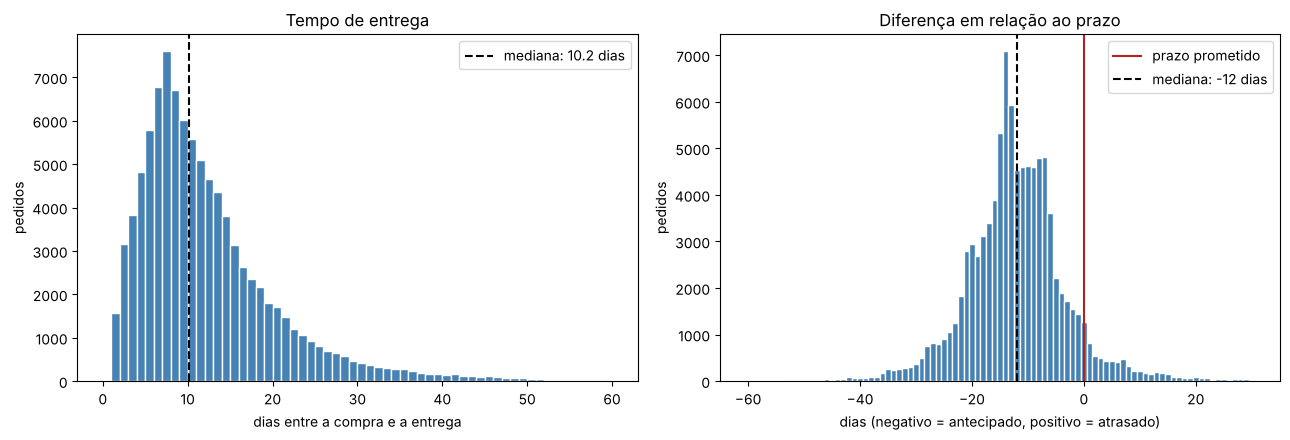

Pedidos fora da janela do gráfico de tempo: 291
Pedidos fora da janela do gráfico de diferença: 363

diferenca_prazo_dias
antecipado         88163
atrasado            6381
no dia do prazo     1280
Name: count, dtype: int64


In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

# Tempo de entrega (dias corridos entre compra e entrega)
eixos[0].hist(base['tempo_entrega_dias'], bins=60, range=(0, 60), color='steelblue', edgecolor='white')
eixos[0].axvline(base['tempo_entrega_dias'].median(), color='black', linestyle='--',
                 label=f"mediana: {base['tempo_entrega_dias'].median():.1f} dias")
eixos[0].set_title('Tempo de entrega')
eixos[0].set_xlabel('dias entre a compra e a entrega')
eixos[0].set_ylabel('pedidos')
eixos[0].legend()

# Diferença em relação ao prazo (um intervalo por dia inteiro)
eixos[1].hist(base['diferenca_prazo_dias'], bins=91, range=(-60.5, 30.5), color='steelblue', edgecolor='white')
eixos[1].axvline(0, color='firebrick', linestyle='-', label='prazo prometido')
eixos[1].axvline(base['diferenca_prazo_dias'].median(), color='black', linestyle='--',
                 label=f"mediana: {base['diferenca_prazo_dias'].median():.0f} dias")
eixos[1].set_title('Diferença em relação ao prazo')
eixos[1].set_xlabel('dias (negativo = antecipado, positivo = atrasado)')
eixos[1].set_ylabel('pedidos')
eixos[1].legend()

plt.tight_layout()
plt.show()

fora_janela_tempo = (base['tempo_entrega_dias'] > 60).sum()
fora_janela_diferenca = ((base['diferenca_prazo_dias'] < -60) | (base['diferenca_prazo_dias'] > 30)).sum()
print('Pedidos fora da janela do gráfico de tempo:', fora_janela_tempo)
print('Pedidos fora da janela do gráfico de diferença:', fora_janela_diferenca)
print()
print(base['diferenca_prazo_dias'].apply(
    lambda d: 'antecipado' if d < 0 else ('no dia do prazo' if d == 0 else 'atrasado')
).value_counts())

**Leitura dos resultados**

**Tempo de entrega.** A distribuição é assimétrica à direita: a maior concentração de pedidos chega entre 5 e 10 dias após a compra, a mediana é de 10,2 dias, e uma cauda longa se estende além de 30 dias. Apenas 291 pedidos (0,3%) levaram mais de 60 dias e ficaram fora da janela do gráfico.

**Diferença em relação ao prazo.** O padrão dominante da base é a entrega antecipada:

| Situação | Pedidos | % da base |
|---|---|---|
| Antecipado | 88.163 | 92,0% |
| No dia do prazo | 1.280 | 1,3% |
| Atrasado | 6.381 | 6,7% |

A mediana é de 12 dias antes do prazo, o que indica que o prazo prometido costuma ser bem mais longo do que o tempo real de entrega. Do lado do atraso, a maior parte dos pedidos se concentra nos primeiros dias após o prazo, e a frequência cai rapidamente depois disso. Apenas 363 pedidos (0,4%) ficaram fora da janela de −60 a +30 dias.

**Implicações para as hipóteses:**

- **H1:** como o atraso é relativamente raro (6,7%) e o tempo de entrega varia muito, a comparação entre pedidos atrasados e no prazo precisa ser feita dentro de faixas de tempo de entrega, para que o efeito do atraso não seja confundido com o efeito de uma espera longa.
- **H3:** a base é muito desbalanceada entre os dois lados do prazo. Há dezenas de milhares de pedidos antecipados e poucos atrasados além de algumas semanas. Por isso, a janela de comparação entre atraso e antecipação será definida pela densidade dos dados, evitando dias com poucos pedidos, em que a nota média fica instável.

### 3.2 Evolução mensal de pedidos, atraso e avaliação negativa

Agrupamos os pedidos pelo mês da compra, momento em que o cliente recebe o prazo prometido, e calculamos três indicadores por mês: número de pedidos, taxa de pedidos fora do prazo (KPI5) e taxa de avaliação negativa (KPI1). O objetivo é duplo: identificar meses com volume muito baixo, que tornariam as taxas instáveis e devem ser avaliados para o recorte temporal, e observar se as taxas de atraso e de avaliação negativa variam juntas ao longo do período.

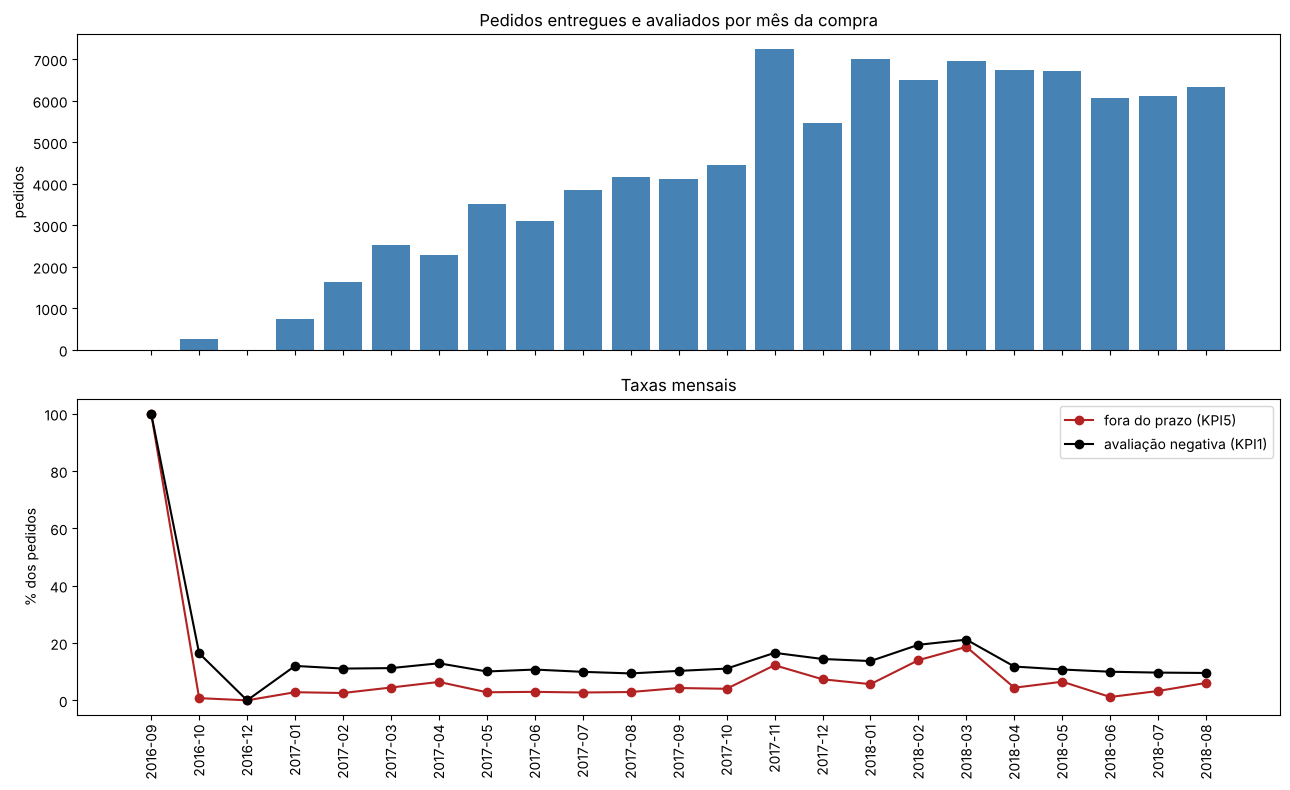

,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa
mes_compra,,,
2016-09,1,100.0,100.0
2016-10,262,0.8,16.4
2016-12,1,0.0,0.0
2017-01,741,2.8,12.0
2017-02,1643,2.6,11.1
2017-03,2527,4.5,11.2
2017-04,2290,6.4,12.9
2017-05,3517,2.8,10.1
2017-06,3111,3.0,10.7


In [12]:
base['mes_compra'] = base['order_purchase_timestamp'].dt.to_period('M')

evolucao_mensal = base.groupby('mes_compra').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean')
)

fig, eixos = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
meses = evolucao_mensal.index.astype(str)

eixos[0].bar(meses, evolucao_mensal['pedidos'], color='steelblue')
eixos[0].set_title('Pedidos entregues e avaliados por mês da compra')
eixos[0].set_ylabel('pedidos')

eixos[1].plot(meses, evolucao_mensal['taxa_fora_do_prazo'] * 100, marker='o', color='firebrick', label='fora do prazo (KPI5)')
eixos[1].plot(meses, evolucao_mensal['taxa_avaliacao_negativa'] * 100, marker='o', color='black', label='avaliação negativa (KPI1)')
eixos[1].set_title('Taxas mensais')
eixos[1].set_ylabel('% dos pedidos')
eixos[1].legend()

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

evolucao_mensal.assign(
    taxa_fora_do_prazo=(evolucao_mensal['taxa_fora_do_prazo'] * 100).round(1),
    taxa_avaliacao_negativa=(evolucao_mensal['taxa_avaliacao_negativa'] * 100).round(1)
)

**Leitura dos resultados**

**Volume.** Os três meses de 2016 têm volume residual: 1 pedido em setembro, 262 em outubro e 1 em dezembro, sem nenhum pedido em novembro. A partir de janeiro de 2017 o volume cresce de forma contínua, passa de 4 mil pedidos mensais no segundo semestre de 2017 e se estabiliza entre 6 e 7 mil em 2018. O maior volume do período ocorre em novembro de 2017 (7.237 pedidos), mês da Black Friday.

**Taxas.** Os 100% de setembro de 2016 vêm de um único pedido e não têm significado estatístico. Ao longo de 2017 e 2018, a taxa de avaliação negativa oscila em torno de 10% a 13% na maior parte dos meses, e a taxa de atraso fica geralmente entre 1% e 7%. Há três momentos em que as duas taxas sobem juntas:

| Mês | Pedidos | Fora do prazo | Avaliação negativa |
|---|---|---|---|
| 2017-11 | 7.237 | 12,3% | 16,6% |
| 2018-02 | 6.507 | 14,0% | 19,4% |
| 2018-03 | 6.948 | 18,7% | 21,2% |

Em março de 2018, quando a taxa de atraso chega ao máximo da série, a taxa de avaliação negativa também atinge o seu máximo. Esse movimento conjunto é coerente com a H1, mas ainda é uma associação agregada por mês, que será testada no nível do pedido na seção 4.

Também é relevante que, mesmo nos meses com atraso baixo (1% a 3%), a taxa de avaliação negativa não cai abaixo de cerca de 9,5%. Ou seja, existe uma parcela de insatisfação que não é explicada pelo atraso, o que dá espaço para a H4 (reclamações sobre o produto).

**Decisão de recorte temporal:** a análise passa a considerar compras de **janeiro de 2017 a agosto de 2018**. Os meses de 2016 são excluídos porque o volume é baixo demais para gerar taxas estáveis e há uma lacuna em novembro de 2016, o que sugere um período inicial de operação ou de coleta incompleta. Os meses de pico (novembro de 2017, fevereiro e março de 2018) são mantidos, porque fazem parte da operação real e concentram justamente a variação de atraso que as hipóteses precisam observar.

### 3.3 Aplicação do recorte temporal

Aplicamos o recorte definido na seção 3.2, mantendo apenas os pedidos com compra entre janeiro de 2017 e agosto de 2018. Em seguida, recalculamos os indicadores gerais da base, que passam a ser a referência para as comparações das próximas seções.

In [13]:
pedidos_antes_do_recorte = len(base)

base = base[base['mes_compra'] >= pd.Period('2017-01', freq='M')].copy()

print('Pedidos antes do recorte:', pedidos_antes_do_recorte)
print('Pedidos excluídos (2016):', pedidos_antes_do_recorte - len(base))
print('Pedidos na base analisada:', len(base))
print('Período:', base['mes_compra'].min(), 'a', base['mes_compra'].max())
print()
print(f"Taxa de pedidos fora do prazo (KPI5): {base['fora_do_prazo'].mean():.1%}")
print(f"Taxa de avaliação negativa (KPI1): {base['avaliacao_negativa'].mean():.1%}")
print(f"Nota média (KPI2): {base['review_score'].mean():.2f}")
print(f"Tempo de entrega mediano (KPI3): {base['tempo_entrega_dias'].median():.1f} dias")
print(f"Diferença mediana em relação ao prazo (KPI4): {base['diferenca_prazo_dias'].median():.0f} dias")

Pedidos antes do recorte: 95824
Pedidos excluídos (2016): 264
Pedidos na base analisada: 95560
Período: 2017-01 a 2018-08

Taxa de pedidos fora do prazo (KPI5): 6.7%
Taxa de avaliação negativa (KPI1): 12.8%
Nota média (KPI2): 4.16
Tempo de entrega mediano (KPI3): 10.2 dias
Diferença mediana em relação ao prazo (KPI4): -12 dias


**Leitura dos resultados**

O recorte removeu 264 pedidos (0,3% da base), e a base analisada passa a ter **95.560 pedidos**, comprados entre janeiro de 2017 e agosto de 2018. Os indicadores gerais praticamente não mudaram, o que confirma que os meses de 2016 não alteravam o retrato da base, apenas acrescentavam instabilidade às séries mensais.

Valores de referência para as próximas seções:

| Indicador | Valor |
|---|---|
| Taxa de avaliação negativa (KPI1) | 12,8% |
| Nota média (KPI2) | 4,16 |
| Tempo de entrega mediano (KPI3) | 10,2 dias |
| Diferença mediana em relação ao prazo (KPI4) | 12 dias antes do prazo |
| Taxa de pedidos fora do prazo (KPI5) | 6,7% |

### 3.4 Indicadores por estado do cliente

Calculamos, para cada estado do cliente, o número de pedidos, a taxa de pedidos fora do prazo, a taxa de avaliação negativa, a nota média e o tempo de entrega mediano. O gráfico de dispersão relaciona a taxa de atraso e a taxa de avaliação negativa de cada estado, com o tamanho do ponto proporcional ao volume de pedidos, já que estados com poucos pedidos produzem taxas menos estáveis.

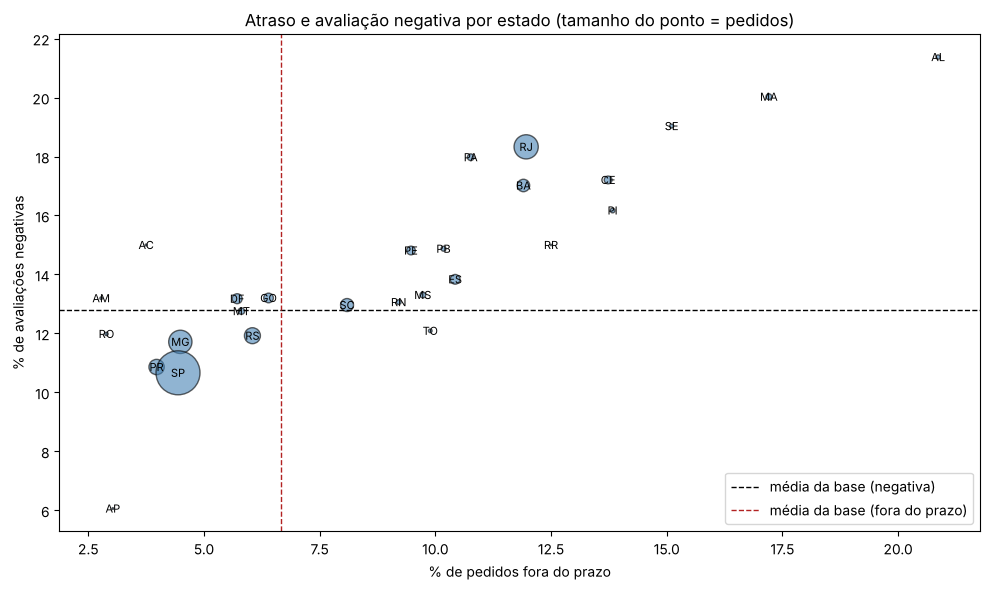

Correlação entre as duas taxas, entre estados: 0.85


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media,tempo_entrega_mediano
customer_state,,,,,
AL,393,20.9,21.4,3.85,22.3
MA,709,17.2,20.0,3.83,19.1
SE,331,15.1,19.0,3.90,17.9
RJ,12172,12.0,18.3,3.97,12.0
PA,929,10.8,18.0,3.91,21.1
CE,1267,13.7,17.2,3.94,18.2
BA,3226,11.9,17.0,3.93,16.9
PI,470,13.8,16.2,3.99,16.3
AC,80,3.8,15.0,4.09,18.4


In [14]:
por_estado = base.groupby('customer_state').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean'),
    tempo_entrega_mediano=('tempo_entrega_dias', 'median')
).sort_values('taxa_avaliacao_negativa', ascending=False)

fig, eixo = plt.subplots(figsize=(10, 6))
eixo.scatter(por_estado['taxa_fora_do_prazo'] * 100, por_estado['taxa_avaliacao_negativa'] * 100,
             s=por_estado['pedidos'] / 40, color='steelblue', alpha=0.6, edgecolor='black')
for estado, linha in por_estado.iterrows():
    eixo.annotate(estado, (linha['taxa_fora_do_prazo'] * 100, linha['taxa_avaliacao_negativa'] * 100),
                  fontsize=8, ha='center', va='center')
eixo.axhline(base['avaliacao_negativa'].mean() * 100, color='black', linestyle='--', linewidth=1, label='média da base (negativa)')
eixo.axvline(base['fora_do_prazo'].mean() * 100, color='firebrick', linestyle='--', linewidth=1, label='média da base (fora do prazo)')
eixo.set_title('Atraso e avaliação negativa por estado (tamanho do ponto = pedidos)')
eixo.set_xlabel('% de pedidos fora do prazo')
eixo.set_ylabel('% de avaliações negativas')
eixo.legend()
plt.tight_layout()
plt.show()

print('Correlação entre as duas taxas, entre estados:',
      round(por_estado['taxa_fora_do_prazo'].corr(por_estado['taxa_avaliacao_negativa']), 2))

por_estado.assign(
    taxa_fora_do_prazo=(por_estado['taxa_fora_do_prazo'] * 100).round(1),
    taxa_avaliacao_negativa=(por_estado['taxa_avaliacao_negativa'] * 100).round(1),
    nota_media=por_estado['nota_media'].round(2),
    tempo_entrega_mediano=por_estado['tempo_entrega_mediano'].round(1)
)

**Leitura dos resultados**

**Relação entre atraso e avaliação negativa.** Entre os estados, as duas taxas andam juntas de forma intensa (correlação de 0,85). Os estados com mais atraso são também os mais insatisfeitos: Alagoas (20,9% fora do prazo; 21,4% de avaliações negativas), Maranhão (17,2%; 20,0%) e Sergipe (15,1%; 19,0%). No extremo oposto ficam São Paulo (4,4%; 10,7%), Paraná (4,0%; 10,9%) e Minas Gerais (4,5%; 11,7%). O Nordeste concentra a maior parte dos estados acima das duas médias.

**Rio de Janeiro.** É o caso de maior peso para o negócio: segundo maior volume da base (12.172 pedidos), 12,0% de atraso e 18,3% de avaliações negativas, quase o dobro do atraso e 7,6 pp a mais de insatisfação do que São Paulo. O tempo de entrega mediano no Rio (12,0 dias) não é muito maior que o de Minas Gerais (10,3 dias), mas a taxa de atraso é quase três vezes maior, o que indica que o problema no Rio está mais no cumprimento do prazo do que na duração da espera.

**Estados do Norte com espera longa.** Amazonas, Amapá, Roraima e Acre têm os maiores tempos de entrega medianos da base (entre 18 e 26 dias), mas, com exceção de Roraima, têm atraso baixo (2,8% a 3,8%) e avaliação negativa na média ou abaixo dela (Amapá com 6,1%). Esperar muito, dentro de um prazo que já era longo, não parece gerar a mesma insatisfação que o atraso. Esse padrão é coerente com a H1, mas os volumes são pequenos (40 a 144 pedidos), então serve apenas como sinal a ser testado no nível do pedido.

**Cuidados na interpretação:**

- A correlação de 0,85 é calculada entre estados, dando o mesmo peso a Roraima (40 pedidos) e a São Paulo (40.171 pedidos). Ela mostra um padrão agregado, não a relação no nível do pedido, que será testada na seção 4.
- São Paulo concentra 42% da base, e São Paulo, Rio de Janeiro e Minas Gerais somam 66,5%. Como o estado se relaciona tanto com o atraso quanto com a avaliação, ele pode atuar como fator de confusão. Por isso, na seção 4, o efeito do atraso será verificado também dentro de São Paulo, o estado com volume suficiente para um teste isolado, como checagem de robustez.

### 3.5 Indicadores por categoria de produto

Calculamos os mesmos indicadores por categoria principal do pedido. Para evitar taxas instáveis, a comparação considera apenas categorias com pelo menos 500 pedidos: com esse volume e uma taxa próxima de 13%, a margem de erro de 95% fica em torno de ±3 pp. Categorias com avaliação negativa alta e atraso próximo da média indicam insatisfação que não é explicada pela entrega, sinal relevante para a H4. As categorias de moda (prefixo `fashion`) são apresentadas à parte, como recorte complementar previsto na decomposição.

Categorias na base: 73
Categorias com pelo menos 500 pedidos: 25
Participação desses pedidos na base: 91.0%
Correlação entre as duas taxas, entre categorias comparáveis: 0.64


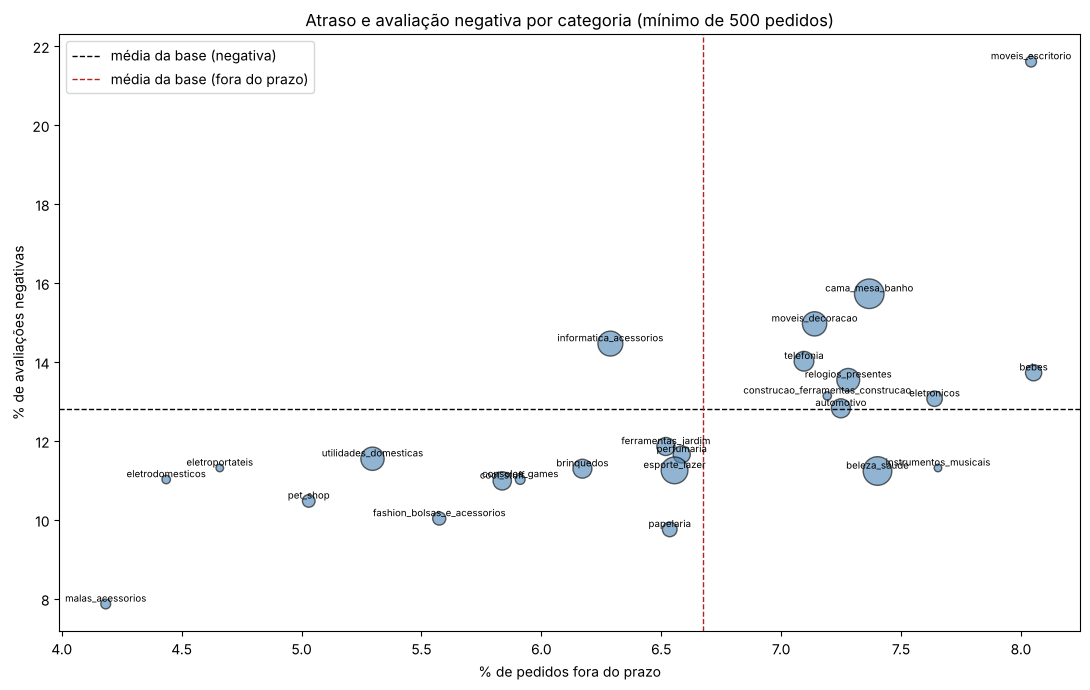


Categorias comparáveis, da maior para a menor taxa de avaliação negativa:


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media,tempo_entrega_mediano
product_category_name,,,,,
moveis_escritorio,1231,8.0,21.6,3.66,18.9
cama_mesa_banho,9067,7.4,15.7,4.01,10.7
moveis_decoracao,6121,7.1,15.0,4.07,10.9
informatica_acessorios,6457,6.3,14.5,4.08,11.1
telefonia,4045,7.1,14.0,4.06,10.8
bebes,2732,8.1,13.7,4.12,10.1
relogios_presentes,5426,7.3,13.5,4.13,10.3
construcao_ferramentas_construcao,723,7.2,13.1,4.13,8.7
eletronicos,2487,7.6,13.1,4.13,11.0



Categorias de moda (todas, independentemente do volume):


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media,tempo_entrega_mediano
product_category_name,,,,,
fashion_roupa_masculina,104,3.8,22.1,3.85,11.1
fashion_roupa_feminina,35,5.7,17.1,3.89,10.8
fashion_underwear_e_moda_praia,116,9.5,16.4,4.01,11.2
fashion_calcados,228,4.4,11.0,4.27,14.2
fashion_bolsas_e_acessorios,1794,5.6,10.0,4.24,9.0
fashion_esporte,24,4.2,4.2,4.54,9.6
fashion_roupa_infanto_juvenil,7,0.0,0.0,5.00,6.4


In [15]:
MINIMO_DE_PEDIDOS = 500

por_categoria = base.groupby('product_category_name').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean'),
    tempo_entrega_mediano=('tempo_entrega_dias', 'median')
).sort_values('taxa_avaliacao_negativa', ascending=False)

categorias_comparaveis = por_categoria[por_categoria['pedidos'] >= MINIMO_DE_PEDIDOS]

print('Categorias na base:', len(por_categoria))
print(f'Categorias com pelo menos {MINIMO_DE_PEDIDOS} pedidos:', len(categorias_comparaveis))
print(f"Participação desses pedidos na base: {categorias_comparaveis['pedidos'].sum() / len(base):.1%}")
print('Correlação entre as duas taxas, entre categorias comparáveis:',
      round(categorias_comparaveis['taxa_fora_do_prazo'].corr(categorias_comparaveis['taxa_avaliacao_negativa']), 2))

fig, eixo = plt.subplots(figsize=(11, 7))
eixo.scatter(categorias_comparaveis['taxa_fora_do_prazo'] * 100, categorias_comparaveis['taxa_avaliacao_negativa'] * 100,
             s=categorias_comparaveis['pedidos'] / 20, color='steelblue', alpha=0.6, edgecolor='black')
for categoria, linha in categorias_comparaveis.iterrows():
    eixo.annotate(categoria, (linha['taxa_fora_do_prazo'] * 100, linha['taxa_avaliacao_negativa'] * 100),
                  fontsize=7, ha='center', va='bottom')
eixo.axhline(base['avaliacao_negativa'].mean() * 100, color='black', linestyle='--', linewidth=1, label='média da base (negativa)')
eixo.axvline(base['fora_do_prazo'].mean() * 100, color='firebrick', linestyle='--', linewidth=1, label='média da base (fora do prazo)')
eixo.set_title(f'Atraso e avaliação negativa por categoria (mínimo de {MINIMO_DE_PEDIDOS} pedidos)')
eixo.set_xlabel('% de pedidos fora do prazo')
eixo.set_ylabel('% de avaliações negativas')
eixo.legend()
plt.tight_layout()
plt.show()

def formatar(tabela):
    return tabela.assign(
        taxa_fora_do_prazo=(tabela['taxa_fora_do_prazo'] * 100).round(1),
        taxa_avaliacao_negativa=(tabela['taxa_avaliacao_negativa'] * 100).round(1),
        nota_media=tabela['nota_media'].round(2),
        tempo_entrega_mediano=tabela['tempo_entrega_mediano'].round(1)
    )

print('\nCategorias comparáveis, da maior para a menor taxa de avaliação negativa:')
display(formatar(categorias_comparaveis))

print('\nCategorias de moda (todas, independentemente do volume):')
display(formatar(por_categoria[por_categoria.index.str.startswith('fashion')]))

**Leitura dos resultados**

A base tem 73 categorias, mas apenas 25 têm pelo menos 500 pedidos. Essas 25 concentram 91,0% da base, então a comparação cobre quase todo o volume sem depender de taxas instáveis.

**A categoria varia pouco no atraso e muito na insatisfação.** Entre as categorias comparáveis, a taxa de atraso fica numa faixa estreita, de 4,2% a 8,1%. Já a taxa de avaliação negativa vai de 7,9% a 21,6%. Entre estados, a taxa de atraso variava de 2,8% a 20,9%. Isso indica que o atraso é explicado principalmente pela geografia, e não pelo tipo de produto. A correlação entre as duas taxas por categoria (0,64) é positiva, mas mais fraca do que por estado (0,85). Isso abre espaço para outros fatores além da entrega.

**Categorias em que a insatisfação vai além do atraso:**

| Categoria | Pedidos | Fora do prazo | Avaliação negativa |
|---|---|---|---|
| moveis_escritorio | 1.231 | 8,0% | 21,6% |
| cama_mesa_banho | 9.067 | 7,4% | 15,7% |
| moveis_decoracao | 6.121 | 7,1% | 15,0% |
| informatica_acessorios | 6.457 | 6,3% | 14,5% |

`moveis_escritorio` é o caso mais extremo: sua taxa de avaliação negativa é a maior entre as categorias comparáveis, bem acima de categorias com atraso parecido, como `bebes` (8,1%; 13,7%) e `eletronicos` (7,6%; 13,1%). `informatica_acessorios` tem atraso abaixo da média da base e, mesmo assim, avaliação negativa acima dela. O caso contrário também existe: `beleza_saude` tem 7,4% de atraso e apenas 11,2% de avaliações negativas.

Esses desvios não provam que o problema seja o produto, mas indicam onde a H4 deve procurar: categorias com insatisfação que o atraso não explica são candidatas naturais a concentrar reclamações sobre qualidade, defeito ou divergência com o anúncio.

**Moda (recorte complementar).** Só `fashion_bolsas_e_acessorios` tem volume suficiente para comparação (1.794 pedidos), e apresenta desempenho melhor que a média (5,6% de atraso; 10,0% de avaliações negativas). As demais categorias de moda têm entre 7 e 228 pedidos. A taxa de 22,1% em `fashion_roupa_masculina`, por exemplo, vem de 104 pedidos, com margem de erro de cerca de ±8 pp.

### 3.6 Relação inicial entre a diferença em relação ao prazo e a avaliação

Calculamos a nota média e a taxa de avaliação negativa para cada valor da diferença em relação ao prazo, entre 40 dias antes e 30 dias depois do prazo, junto com o número de pedidos em cada dia. O objetivo é observar visualmente se a avaliação muda de patamar quando o pedido ultrapassa o prazo (H1) e se a inclinação da curva é diferente entre o lado do atraso e o lado da antecipação (H3). O número de pedidos por dia indica até onde as médias são estáveis o bastante para entrar nos testes.

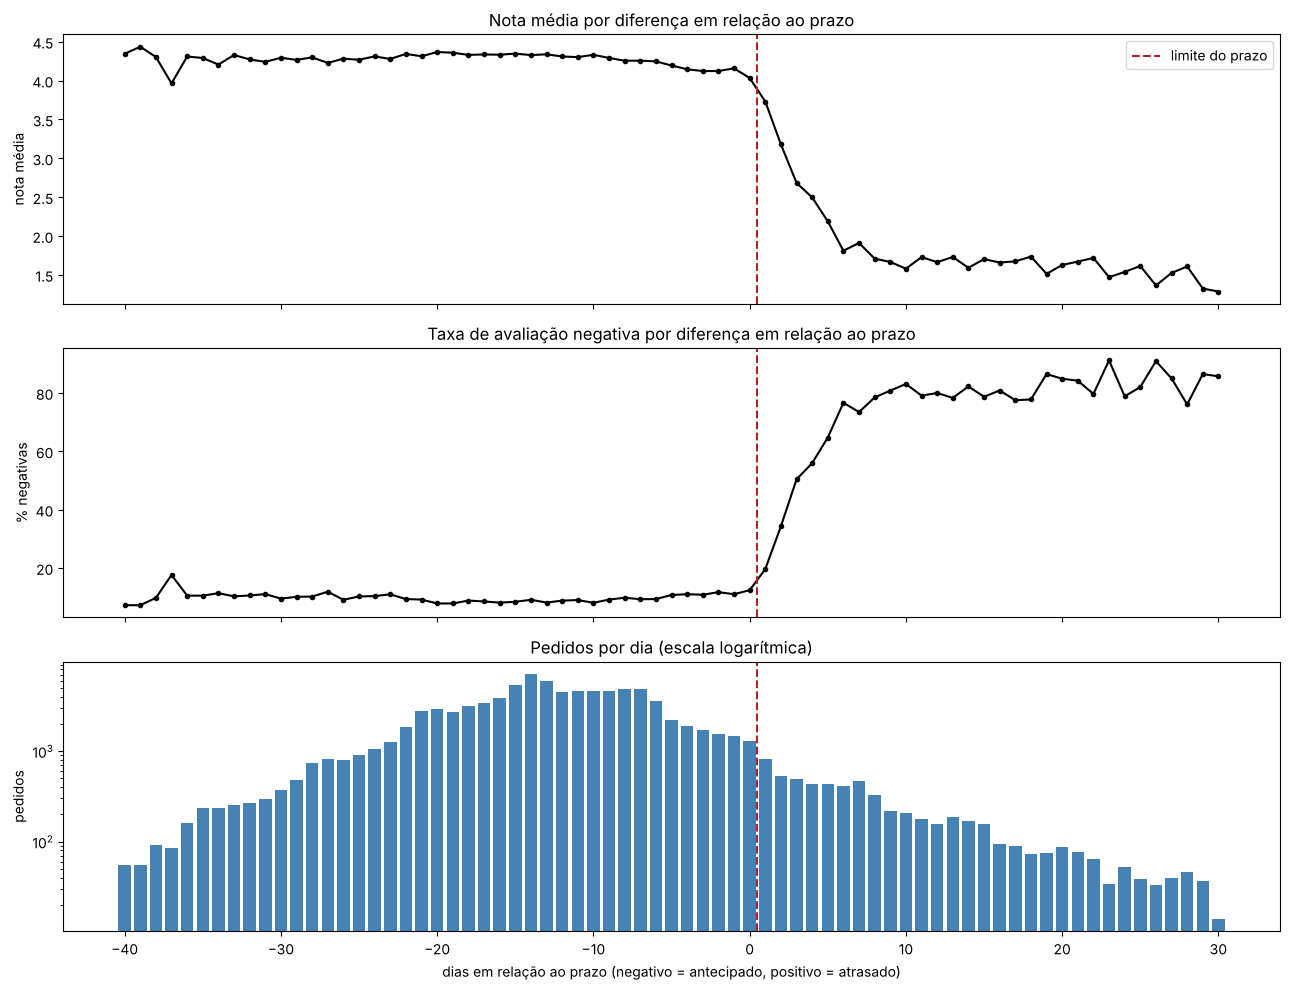

,pedidos,nota_media,taxa_avaliacao_negativa
diferenca_prazo_dias,,,
-30,367,4.29,9.5
-20,2947,4.37,7.9
-15,5317,4.35,8.4
-10,4618,4.33,8.1
-5,2208,4.19,10.8
-3,1713,4.12,10.9
-2,1540,4.12,11.8
-1,1449,4.16,11.0
0,1280,4.03,12.4


In [16]:
JANELA_EXPLORATORIA = (-40, 30)

por_dia = base[base['diferenca_prazo_dias'].between(*JANELA_EXPLORATORIA)].groupby('diferenca_prazo_dias').agg(
    pedidos=('order_id', 'count'),
    nota_media=('review_score', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean')
)

fig, eixos = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

eixos[0].plot(por_dia.index, por_dia['nota_media'], marker='o', markersize=3, color='black')
eixos[0].axvline(0.5, color='firebrick', linestyle='--', label='limite do prazo')
eixos[0].set_title('Nota média por diferença em relação ao prazo')
eixos[0].set_ylabel('nota média')
eixos[0].legend()

eixos[1].plot(por_dia.index, por_dia['taxa_avaliacao_negativa'] * 100, marker='o', markersize=3, color='black')
eixos[1].axvline(0.5, color='firebrick', linestyle='--')
eixos[1].set_title('Taxa de avaliação negativa por diferença em relação ao prazo')
eixos[1].set_ylabel('% negativas')

eixos[2].bar(por_dia.index, por_dia['pedidos'], color='steelblue')
eixos[2].axvline(0.5, color='firebrick', linestyle='--')
eixos[2].set_yscale('log')
eixos[2].set_title('Pedidos por dia (escala logarítmica)')
eixos[2].set_ylabel('pedidos')
eixos[2].set_xlabel('dias em relação ao prazo (negativo = antecipado, positivo = atrasado)')

plt.tight_layout()
plt.show()

DIAS_EM_DESTAQUE = [-30, -20, -15, -10, -5, -3, -2, -1, 0, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30]
por_dia.loc[por_dia.index.isin(DIAS_EM_DESTAQUE)].assign(
    nota_media=por_dia['nota_media'].round(2),
    taxa_avaliacao_negativa=(por_dia['taxa_avaliacao_negativa'] * 100).round(1)
)

**Leitura dos resultados**

**Lado da antecipação.** A nota média é praticamente estável entre 40 e 5 dias antes do prazo, em torno de 4,3, com taxa de avaliação negativa entre 8% e 11%. Chegar 30 dias antes (4,29) não rende avaliação melhor do que chegar 10 dias antes (4,33). Há uma leve queda à medida que a entrega se aproxima do prazo: 4,19 a 5 dias antes e 4,03 no próprio dia do prazo.

**Lado do atraso.** A partir do primeiro dia de atraso, a avaliação cai de forma acentuada e contínua durante cerca de uma semana:

| Dias após o prazo | Nota média | Avaliação negativa |
|---|---|---|
| 0 (no dia) | 4,03 | 12,4% |
| 1 | 3,73 | 19,7% |
| 3 | 2,68 | 50,4% |
| 5 | 2,19 | 64,7% |
| 7 | 1,91 | 73,5% |
| 10 | 1,58 | 83,1% |

A partir de cerca de 8 a 10 dias de atraso, a curva se estabiliza: a nota fica em torno de 1,6 e a taxa de avaliação negativa em torno de 80%. Mais dias de atraso já não pioram muito a avaliação, porque ela já está perto do mínimo possível.

**O que isso sugere para as hipóteses:**

- **H1:** a ruptura acontece exatamente no limite do prazo, e não ao longo do tempo de espera. Isso é coerente com a ideia de que o cliente reage à quebra da promessa. O teste formal precisa comparar pedidos com tempo de entrega semelhante, o que é feito na seção 4.1.
- **H2:** a queda depois do prazo não é um degrau único, mas uma rampa de vários dias. No primeiro dia de atraso, a taxa de avaliação negativa (19,7%) ainda está longe do patamar de 80%. Uma explicação possível, a ser testada na seção 4.2, é que a proporção de clientes que respondem à pesquisa antes de receber o pedido aumenta à medida que o atraso cresce.
- **H3:** visualmente, a inclinação é quase nula do lado da antecipação e muito acentuada do lado do atraso, o que é coerente com a assimetria prevista pela aversão à perda. Como a curva do atraso se estabiliza depois de cerca de uma semana, uma comparação de inclinações por reta só faz sentido numa janela próxima ao prazo. Nos 7 primeiros dias de atraso, cada dia tem mais de 400 pedidos, enquanto a partir de 20 dias de atraso há menos de 100 pedidos por dia. A janela da H3 será definida na seção 4.3 com base nesses dois critérios: volume por dia e trecho anterior à estabilização.

## 4. Teste das hipóteses

Nível de significância adotado: α = 5%. Quando uma hipótese envolve várias comparações simultâneas, aplicamos a correção de Bonferroni. Além dos p-valores, reportamos o tamanho do efeito (diferença em pontos percentuais e em pontos de nota), porque, numa base com quase 100 mil pedidos, diferenças pequenas tendem a ser estatisticamente significativas sem serem relevantes para o negócio. Como os dados são observacionais, os resultados indicam associação, e não causalidade.

### 4.1 H1: quebra da promessa de prazo versus tempo de espera

**Hipótese:** a quebra da promessa de prazo está associada a uma piora da avaliação maior do que o tempo de espera em si.

Pedidos atrasados tendem a ser também os que levam mais tempo para chegar, então uma comparação direta entre atrasados e não atrasados misturaria os dois efeitos. Para separá-los, dividimos os pedidos em faixas de tempo de entrega e comparamos atrasados e não atrasados dentro de cada faixa. Se a diferença persistir em todas as faixas, o atraso tem associação com a avaliação que não é explicada apenas pela duração da espera.

Nesta primeira etapa, apresentamos os números descritivos por faixa, para verificar o volume de cada grupo antes dos testes.

In [17]:
FAIXAS_DE_TEMPO = [0, 7, 14, 21, 30, float('inf')]
ROTULOS_DAS_FAIXAS = ['0 a 7 dias', '7 a 14 dias', '14 a 21 dias', '21 a 30 dias', 'acima de 30 dias']

base['faixa_tempo_entrega'] = pd.cut(base['tempo_entrega_dias'], bins=FAIXAS_DE_TEMPO,
                                     labels=ROTULOS_DAS_FAIXAS, right=False)

h1_descritivo = base.groupby(['faixa_tempo_entrega', 'fora_do_prazo'], observed=True).agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean')
).unstack('fora_do_prazo')

h1_descritivo.columns = [f'{indicador} ({"fora do prazo" if fora else "no prazo"})'
                         for indicador, fora in h1_descritivo.columns]

h1_descritivo['diferenca_negativa_pp'] = (
    h1_descritivo['taxa_avaliacao_negativa (fora do prazo)'] - h1_descritivo['taxa_avaliacao_negativa (no prazo)']
) * 100
h1_descritivo['diferenca_nota'] = (
    h1_descritivo['nota_media (fora do prazo)'] - h1_descritivo['nota_media (no prazo)']
)

for coluna in ['taxa_avaliacao_negativa (no prazo)', 'taxa_avaliacao_negativa (fora do prazo)']:
    h1_descritivo[coluna] = h1_descritivo[coluna] * 100

h1_descritivo.round(2)

,pedidos (no prazo),pedidos (fora do prazo),taxa_avaliacao_negativa (no prazo),taxa_avaliacao_negativa (fora do prazo),nota_media (no prazo),nota_media (fora do prazo),diferenca_negativa_pp,diferenca_nota
faixa_tempo_entrega,,,,,,,,
0 a 7 dias,25866,58,7.44,12.07,4.42,3.98,4.63,-0.44
7 a 14 dias,39584,313,8.77,32.59,4.32,3.35,23.82,-0.97
14 a 21 dias,16997,526,10.70,43.16,4.18,2.91,32.46,-1.26
21 a 30 dias,5823,2009,14.39,53.01,3.96,2.59,38.62,-1.37
acima de 30 dias,912,3472,21.49,74.31,3.67,1.86,52.82,-1.81


**Leitura dos resultados descritivos**

Em todas as faixas de tempo de entrega, os pedidos fora do prazo têm taxa de avaliação negativa maior e nota média menor do que os pedidos no prazo com espera semelhante.

Para dimensionar os dois efeitos, comparamos o que acontece em cada eixo:

- **Efeito da espera (sem atraso):** entre os pedidos no prazo, a taxa de avaliação negativa sobe de 7,4% (até 7 dias) para 21,5% (acima de 30 dias). Ou seja, uma espera de mais de um mês, dentro do prazo, acrescenta cerca de 14 pp de insatisfação.
- **Efeito do atraso (com espera semelhante):** dentro de uma mesma faixa de tempo, estar fora do prazo acrescenta de 23,8 pp (7 a 14 dias) a 52,8 pp (acima de 30 dias) de avaliações negativas.

Na faixa de 14 a 21 dias, por exemplo, um pedido no prazo tem 10,7% de avaliações negativas, e um pedido atrasado, que levou praticamente o mesmo tempo para chegar, tem 43,2%. A diferença de 32,5 pp é maior do que todo o efeito da espera observado entre os pedidos no prazo.

**Dois cuidados:**

- A faixa de 0 a 7 dias tem apenas 58 pedidos atrasados. A diferença observada (4,6 pp) pode não ser estatisticamente confiável, o que será verificado no teste.
- A diferença cresce nas faixas mais longas em parte porque elas reúnem atrasos maiores: um pedido que levou mais de 30 dias e está fora do prazo tende a ter mais dias de atraso do que um que levou de 7 a 14 dias. O efeito por dia de atraso é tratado na H3.

**Teste estatístico por faixa de tempo de entrega**

Hipóteses testadas em cada faixa:

- **H₀:** a taxa de avaliação negativa (e a distribuição das notas) é igual entre pedidos no prazo e fora do prazo.
- **H₁:** a taxa de avaliação negativa (e a distribuição das notas) é diferente entre os dois grupos.

Para a taxa de avaliação negativa (KPI1), usamos o teste z para duas proporções. Para a nota (KPI2), usamos o teste de Mann-Whitney, adequado porque a nota é uma variável ordinal, concentrada no valor 5 e sem distribuição normal. Como são cinco comparações simultâneas, aplicamos a correção de Bonferroni: cada faixa é considerada significativa apenas se os dois testes tiverem p-valor abaixo de 0,05 / 5 = 0,01.

In [18]:
ALFA = 0.05
NUMERO_DE_COMPARACOES = len(ROTULOS_DAS_FAIXAS)
ALFA_BONFERRONI = ALFA / NUMERO_DE_COMPARACOES


def teste_z_proporcoes(sucessos_a, total_a, sucessos_b, total_b):
    """Teste z bilateral para a diferença entre duas proporções."""
    p_a = sucessos_a / total_a
    p_b = sucessos_b / total_b
    p_combinada = (sucessos_a + sucessos_b) / (total_a + total_b)
    erro_padrao = math.sqrt(p_combinada * (1 - p_combinada) * (1 / total_a + 1 / total_b))
    z = (p_a - p_b) / erro_padrao
    p_valor = 2 * (1 - st.norm.cdf(abs(z)))
    return z, p_valor


resultados_h1 = []
for faixa in ROTULOS_DAS_FAIXAS:
    grupo = base[base['faixa_tempo_entrega'] == faixa]
    no_prazo = grupo[~grupo['fora_do_prazo']]
    fora_do_prazo = grupo[grupo['fora_do_prazo']]

    z, p_valor_negativa = teste_z_proporcoes(
        fora_do_prazo['avaliacao_negativa'].sum(), len(fora_do_prazo),
        no_prazo['avaliacao_negativa'].sum(), len(no_prazo)
    )
    p_valor_nota = st.mannwhitneyu(
        fora_do_prazo['review_score'], no_prazo['review_score'], alternative='two-sided'
    ).pvalue

    resultados_h1.append({
        'faixa': faixa,
        'pedidos fora do prazo': len(fora_do_prazo),
        'diferença na taxa negativa (pp)': round((fora_do_prazo['avaliacao_negativa'].mean()
                                                  - no_prazo['avaliacao_negativa'].mean()) * 100, 1),
        'p-valor (teste z)': p_valor_negativa,
        'diferença na nota': round(fora_do_prazo['review_score'].mean() - no_prazo['review_score'].mean(), 2),
        'p-valor (Mann-Whitney)': p_valor_nota,
        'significativo após Bonferroni': (p_valor_negativa < ALFA_BONFERRONI) and (p_valor_nota < ALFA_BONFERRONI)
    })

print(f'Alfa ajustado por Bonferroni: {ALFA_BONFERRONI:.3f}')
pd.DataFrame(resultados_h1).set_index('faixa')

Alfa ajustado por Bonferroni: 0.010


,pedidos fora do prazo,diferença na taxa negativa (pp),p-valor (teste z),diferença na nota,p-valor (Mann-Whitney),significativo após Bonferroni
faixa,,,,,,
0 a 7 dias,58,4.6,0.179712,-0.44,1.250413e-03,False
7 a 14 dias,313,23.8,0.000000,-0.97,1.567407e-33,True
14 a 21 dias,526,32.5,0.000000,-1.26,5.245312e-79,True
21 a 30 dias,2009,38.6,0.000000,-1.37,4.212635e-218,True
acima de 30 dias,3472,52.8,0.000000,-1.81,2.011668e-204,True


**Leitura dos resultados**

Os p-valores exibidos como 0,000000 são menores do que a precisão numérica do cálculo (abaixo de 10⁻¹⁶), ou seja, praticamente nulos.

- **Faixas de 7 a 14, 14 a 21, 21 a 30 e acima de 30 dias:** rejeitamos H₀ nos dois testes, com folga em relação ao α ajustado de 0,01. Dentro de cada faixa, os pedidos atrasados têm de 23,8 a 52,8 pp a mais de avaliações negativas e de 0,97 a 1,81 ponto a menos na nota média.
- **Faixa de 0 a 7 dias:** a diferença na taxa de avaliação negativa (4,6 pp) não é significativa (p = 0,18). A diferença na nota (−0,44) passa no Mann-Whitney (p = 0,001), mas, pelo critério adotado, que exige os dois testes, a faixa não é considerada significativa. Com apenas 58 pedidos atrasados, o teste tem pouco poder para detectar diferenças nessa faixa.

As quatro faixas significativas reúnem 6.320 dos 6.378 pedidos atrasados da base (99,1%).

**Conclusão sobre a H1:** os dados sustentam a hipótese. Com tempo de espera semelhante, estar fora do prazo está associado a uma piora expressiva da avaliação, maior do que o efeito de esperar mais dentro do prazo (cerca de 14 pp entre a faixa mais curta e a mais longa, como visto no descritivo). Esse resultado é coerente com o modelo de desconfirmação de expectativas (Oliver, 1980): o que pesa na avaliação é a distância entre o prometido e o entregue, mais do que o tempo absoluto de espera.

**Checagem de robustez: o efeito se mantém dentro de São Paulo?**

Como o estado do cliente está associado tanto ao atraso quanto à avaliação (seção 3.4), ele pode atuar como fator de confusão. Para verificar se o resultado da H1 depende das diferenças entre estados, repetimos o mesmo teste por faixa de tempo de entrega considerando apenas os pedidos de São Paulo, único estado com volume suficiente para essa análise isolada. Os critérios são os mesmos: teste z para a taxa de avaliação negativa, Mann-Whitney para a nota e α ajustado por Bonferroni de 0,01.

In [19]:
def comparar_atraso_por_faixa(dados):
    """Compara pedidos no prazo e fora do prazo dentro de cada faixa de tempo de entrega."""
    resultados = []
    for faixa in ROTULOS_DAS_FAIXAS:
        grupo = dados[dados['faixa_tempo_entrega'] == faixa]
        no_prazo = grupo[~grupo['fora_do_prazo']]
        fora_do_prazo = grupo[grupo['fora_do_prazo']]

        z, p_valor_negativa = teste_z_proporcoes(
            fora_do_prazo['avaliacao_negativa'].sum(), len(fora_do_prazo),
            no_prazo['avaliacao_negativa'].sum(), len(no_prazo)
        )
        p_valor_nota = st.mannwhitneyu(
            fora_do_prazo['review_score'], no_prazo['review_score'], alternative='two-sided'
        ).pvalue

        resultados.append({
            'faixa': faixa,
            'pedidos no prazo': len(no_prazo),
            'pedidos fora do prazo': len(fora_do_prazo),
            'taxa negativa no prazo (%)': round(no_prazo['avaliacao_negativa'].mean() * 100, 1),
            'taxa negativa fora do prazo (%)': round(fora_do_prazo['avaliacao_negativa'].mean() * 100, 1),
            'diferença na taxa negativa (pp)': round((fora_do_prazo['avaliacao_negativa'].mean()
                                                      - no_prazo['avaliacao_negativa'].mean()) * 100, 1),
            'p-valor (teste z)': p_valor_negativa,
            'diferença na nota': round(fora_do_prazo['review_score'].mean() - no_prazo['review_score'].mean(), 2),
            'p-valor (Mann-Whitney)': p_valor_nota,
            'significativo após Bonferroni': (p_valor_negativa < ALFA_BONFERRONI) and (p_valor_nota < ALFA_BONFERRONI)
        })
    return pd.DataFrame(resultados).set_index('faixa')


pedidos_sp = base[base['customer_state'] == 'SP']
print('Pedidos de São Paulo:', len(pedidos_sp))
print('Pedidos de São Paulo fora do prazo:', pedidos_sp['fora_do_prazo'].sum())
comparar_atraso_por_faixa(pedidos_sp)

Pedidos de São Paulo: 40171
Pedidos de São Paulo fora do prazo: 1783


,pedidos no prazo,pedidos fora do prazo,taxa negativa no prazo (%),taxa negativa fora do prazo (%),diferença na taxa negativa (pp),p-valor (teste z),diferença na nota,p-valor (Mann-Whitney),significativo após Bonferroni
faixa,,,,,,,,,
0 a 7 dias,18823,52,7.3,11.5,4.2,2.469691e-01,-0.45,1.237161e-03,False
7 a 14 dias,15533,281,9.1,31.3,22.3,0.000000e+00,-0.91,2.175581e-27,True
14 a 21 dias,3430,379,12.0,47.0,35.0,0.000000e+00,-1.30,9.815639e-53,True
21 a 30 dias,532,650,17.3,60.2,42.9,0.000000e+00,-1.47,1.690690e-50,True
acima de 30 dias,70,421,34.3,72.7,38.4,2.345037e-10,-1.38,2.630170e-11,True


**Leitura dos resultados**

Dentro de São Paulo (40.171 pedidos, 1.783 fora do prazo), o padrão se repete. Nas quatro faixas a partir de 7 dias, a diferença é significativa nos dois testes, com magnitude semelhante à da base completa: de 22,3 a 42,9 pp a mais de avaliações negativas entre os pedidos atrasados. Na faixa de 0 a 7 dias, assim como na base completa, a diferença na taxa de avaliação negativa não é significativa (52 pedidos atrasados).

Como o efeito aparece com a mesma intensidade dentro de um único estado, ele não é explicado pelas diferenças regionais vistas na seção 3.4. O resultado da H1 se mantém.

**Síntese da H1:** com tempo de espera semelhante, pedidos fora do prazo têm uma taxa de avaliação negativa de 22 a 53 pp maior do que pedidos no prazo, em todas as faixas com volume suficiente para teste (99,1% dos atrasos). O efeito se mantém dentro de São Paulo. A quebra da promessa está associada a uma piora da avaliação maior do que o tempo de espera em si.

### 4.2 H2: avaliação respondida antes da entrega

**Hipótese:** entre os pedidos atrasados, a avaliação respondida antes da entrega é pior do que a respondida depois da entrega.

Segundo a descrição da base no Kaggle, a pesquisa de satisfação é enviada ao cliente na data estimada de entrega. Em um pedido atrasado, portanto, o cliente pode receber a pesquisa antes do produto e avaliar uma compra que ainda não recebeu. A variável `avaliacao_antes_da_entrega`, criada na seção 2.7, identifica esses casos.

Como a proporção de respostas antes da entrega tende a crescer com o tamanho do atraso, a comparação é feita dentro de faixas de dias de atraso. Assim, a diferença observada pode ser atribuída ao momento da resposta, e não a atrasos maiores. As faixas acompanham o formato da curva da seção 3.6: 1 a 3 dias e 4 a 7 dias (trecho de queda acentuada), 8 a 14 dias e acima de 14 dias (trecho estabilizado).

In [20]:
pedidos_atrasados = base[base['fora_do_prazo']].copy()

FAIXAS_DE_ATRASO = [0, 3, 7, 14, float('inf')]
ROTULOS_DE_ATRASO = ['1 a 3 dias', '4 a 7 dias', '8 a 14 dias', 'acima de 14 dias']
pedidos_atrasados['faixa_atraso'] = pd.cut(pedidos_atrasados['diferenca_prazo_dias'],
                                           bins=FAIXAS_DE_ATRASO, labels=ROTULOS_DE_ATRASO)

print('Pedidos atrasados:', len(pedidos_atrasados))
print(f"Respondidos antes da entrega: {pedidos_atrasados['avaliacao_antes_da_entrega'].sum()} "
      f"({pedidos_atrasados['avaliacao_antes_da_entrega'].mean():.1%})")
print('Pedidos no prazo respondidos antes da entrega:',
      base.loc[~base['fora_do_prazo'], 'avaliacao_antes_da_entrega'].sum())

print('\nVisão geral dos pedidos atrasados:')
display(pedidos_atrasados.groupby('avaliacao_antes_da_entrega').agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1)),
    nota_media=('review_score', lambda x: round(x.mean(), 2))
))

print('\nPor faixa de atraso:')
h2_descritivo = pedidos_atrasados.groupby(['faixa_atraso', 'avaliacao_antes_da_entrega'], observed=True).agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean')
).unstack('avaliacao_antes_da_entrega')

h2_descritivo.columns = [f'{indicador} ({"antes da entrega" if antes else "depois da entrega"})'
                         for indicador, antes in h2_descritivo.columns]
h2_descritivo['% respondidos antes da entrega'] = (
    h2_descritivo['pedidos (antes da entrega)']
    / (h2_descritivo['pedidos (antes da entrega)'] + h2_descritivo['pedidos (depois da entrega)']) * 100
)
for coluna in ['taxa_avaliacao_negativa (antes da entrega)', 'taxa_avaliacao_negativa (depois da entrega)']:
    h2_descritivo[coluna] = h2_descritivo[coluna] * 100

h2_descritivo.round(2)

Pedidos atrasados: 6378
Respondidos antes da entrega: 4471 (70.1%)
Pedidos no prazo respondidos antes da entrega: 177

Visão geral dos pedidos atrasados:


,pedidos,taxa_avaliacao_negativa,nota_media
avaliacao_antes_da_entrega,,,
False,1907,19.5,3.72
True,4471,80.7,1.65



Por faixa de atraso:


,pedidos (depois da entrega),pedidos (antes da entrega),taxa_avaliacao_negativa (depois da entrega),taxa_avaliacao_negativa (antes da entrega),nota_media (depois da entrega),nota_media (antes da entrega),% respondidos antes da entrega
faixa_atraso,,,,,,,
1 a 3 dias,1435,416,18.61,78.85,3.75,1.72,22.47
4 a 7 dias,396,1352,20.45,81.51,3.69,1.64,77.35
8 a 14 dias,57,1389,26.32,82.36,3.53,1.59,96.06
acima de 14 dias,19,1314,42.11,78.84,2.89,1.71,98.57


**Leitura dos resultados descritivos**

Dos 6.378 pedidos atrasados, 4.471 (70,1%) tiveram a pesquisa respondida antes da entrega. Entre os pedidos no prazo, isso aconteceu em apenas 177 casos, o que confirma que responder antes de receber o produto é, na prática, um fenômeno dos pedidos atrasados.

**A diferença é grande e estável em todas as faixas de atraso.** Entre os atrasados, quem respondeu antes da entrega tem cerca de 80% de avaliações negativas, e quem respondeu depois tem entre 19% e 42%:

| Faixa de atraso | Negativas (depois da entrega) | Negativas (antes da entrega) | % respondidos antes |
|---|---|---|---|
| 1 a 3 dias | 18,6% | 78,9% | 22,5% |
| 4 a 7 dias | 20,4% | 81,5% | 77,4% |
| 8 a 14 dias | 26,3% | 82,4% | 96,1% |
| acima de 14 dias | 42,1% | 78,8% | 98,6% |

Dois padrões chamam a atenção:

- **Dentro de cada faixa, o momento da resposta pesa mais do que o tamanho do atraso.** A taxa de avaliação negativa de quem respondeu antes da entrega fica praticamente constante (79% a 82%), seja o atraso de 2 dias ou de 3 semanas.
- **A proporção de respostas antes da entrega acompanha a rampa da seção 3.6.** Ela sobe de 22,5% nos atrasos de 1 a 3 dias para 77,4% nos de 4 a 7 dias e passa de 96% a partir de 8 dias. Isso oferece uma explicação para o formato da curva: a avaliação média dos atrasados piora ao longo da primeira semana porque, a cada dia de atraso, uma parcela maior dos clientes responde à pesquisa sem ter recebido o produto. Quando quase todos passam a responder antes, a curva se estabiliza.

**Cuidados:** as faixas acima de 7 dias têm poucos pedidos respondidos depois da entrega (57 e 19), então as taxas desse grupo são instáveis. Além disso, o momento da resposta é uma escolha do cliente: clientes mais insatisfeitos podem responder mais rápido. Por isso, o resultado indica associação entre responder antes da entrega e avaliar pior, e não prova que o momento da pesquisa cause a avaliação negativa.

**Teste estatístico por faixa de atraso**

Hipóteses testadas em cada faixa de atraso:

- **H₀:** entre os pedidos atrasados, a taxa de avaliação negativa (e a distribuição das notas) é igual para avaliações respondidas antes e depois da entrega.
- **H₁:** a taxa de avaliação negativa (e a distribuição das notas) é diferente entre os dois grupos.

Utilizamos os mesmos testes da seção 4.1 (teste z para duas proporções e Mann-Whitney). Com quatro faixas, o α ajustado por Bonferroni é de 0,05 / 4 = 0,0125, e a faixa é considerada significativa apenas se os dois testes ficarem abaixo desse valor.

In [21]:
ALFA_BONFERRONI_H2 = ALFA / len(ROTULOS_DE_ATRASO)

resultados_h2 = []
for faixa in ROTULOS_DE_ATRASO:
    grupo = pedidos_atrasados[pedidos_atrasados['faixa_atraso'] == faixa]
    antes = grupo[grupo['avaliacao_antes_da_entrega']]
    depois = grupo[~grupo['avaliacao_antes_da_entrega']]

    z, p_valor_negativa = teste_z_proporcoes(
        antes['avaliacao_negativa'].sum(), len(antes),
        depois['avaliacao_negativa'].sum(), len(depois)
    )
    p_valor_nota = st.mannwhitneyu(
        antes['review_score'], depois['review_score'], alternative='two-sided'
    ).pvalue

    resultados_h2.append({
        'faixa de atraso': faixa,
        'respondidos antes': len(antes),
        'respondidos depois': len(depois),
        'diferença na taxa negativa (pp)': round((antes['avaliacao_negativa'].mean()
                                                  - depois['avaliacao_negativa'].mean()) * 100, 1),
        'p-valor (teste z)': p_valor_negativa,
        'diferença na nota': round(antes['review_score'].mean() - depois['review_score'].mean(), 2),
        'p-valor (Mann-Whitney)': p_valor_nota,
        'significativo após Bonferroni': (p_valor_negativa < ALFA_BONFERRONI_H2) and (p_valor_nota < ALFA_BONFERRONI_H2)
    })

print(f'Alfa ajustado por Bonferroni: {ALFA_BONFERRONI_H2:.4f}')
pd.DataFrame(resultados_h2).set_index('faixa de atraso')

Alfa ajustado por Bonferroni: 0.0125


,respondidos antes,respondidos depois,diferença na taxa negativa (pp),p-valor (teste z),diferença na nota,p-valor (Mann-Whitney),significativo após Bonferroni
faixa de atraso,,,,,,,
1 a 3 dias,416,1435,60.2,0.000000,-2.02,8.706412e-104,True
4 a 7 dias,1352,396,61.1,0.000000,-2.05,1.735985e-117,True
8 a 14 dias,1389,57,56.0,0.000000,-1.93,3.014637e-22,True
acima de 14 dias,1314,19,36.7,0.000114,-1.19,1.006521e-04,True


**Leitura dos resultados**

Rejeitamos H₀ nas quatro faixas de atraso, nos dois testes, com p-valores abaixo do α ajustado de 0,0125. Entre os pedidos atrasados, responder à pesquisa antes da entrega está associado a:

- **56 a 61 pp a mais de avaliações negativas** e cerca de **2 pontos a menos na nota média** nas faixas de 1 a 14 dias de atraso, que reúnem a grande maioria dos casos;
- 36,7 pp a mais de avaliações negativas e 1,19 ponto a menos na nota na faixa acima de 14 dias. Esse efeito menor deve ser lido com cautela, porque o grupo que respondeu depois da entrega tem apenas 19 pedidos.

**Conclusão sobre a H2:** os dados sustentam a hipótese. Entre os pedidos atrasados, quem responde à pesquisa antes de receber o produto avalia muito pior do que quem responde depois, e isso vale em todas as faixas de atraso, ou seja, não é explicado pelo tamanho do atraso. Combinado com o padrão da seção 3.6, o resultado sugere que boa parte da piora associada ao atraso se concentra nas avaliações feitas antes da entrega. Por se tratar de dados observacionais em que o momento da resposta é escolhido pelo cliente, a relação causal entre o envio da pesquisa na data estimada e a avaliação negativa não pode ser afirmada a partir desta base e é uma candidata natural a teste A/B, a ser proposto nas recomendações.

### 4.3 H3: assimetria entre atraso e antecipação

**Hipótese:** cada dia de atraso reduz a avaliação mais do que cada dia de antecipação a aumenta, em linha com a aversão à perda (Kahneman e Tversky, 1979).

Ajustamos duas regressões lineares simples da nota em função da diferença em relação ao prazo: uma do lado da antecipação (de 7 dias antes até o dia do prazo) e outra do lado do atraso (de 1 a 7 dias depois). A inclinação de cada reta indica a variação média da nota por dia. As retas são ajustadas com os pedidos individuais, de modo que cada dia pesa conforme o seu volume.

A janela de 7 dias foi definida na seção 3.6: todos os dias desse intervalo têm mais de 400 pedidos, e ele antecede o trecho em que a curva do atraso se estabiliza. Para verificar se a conclusão depende dessa escolha, repetimos a análise com janelas de 5 e 10 dias.

- **H₀:** a variação da nota por dia é igual, em módulo, dos dois lados do prazo.
- **H₁:** a variação da nota por dia de atraso é maior, em módulo, do que a variação por dia de antecipação.

A comparação usa um teste z unilateral para a diferença entre os módulos das inclinações, com α = 5%.

Nota média (KPI2):


,pedidos antecipação,pedidos atraso,inclinação antecipação,IC 95% antecipação,inclinação atraso,IC 95% atraso,razão entre os módulos,z,p-valor
janela (dias),,,,,,,,,
5,10093,2721,-0.0215,"(-0.0355, -0.0075)",-0.3904,"(-0.4306, -0.3502)",18.1,17.0,0.0
7,18509,3599,-0.0275,"(-0.035, -0.02)",-0.3217,"(-0.3454, -0.2981)",11.7,23.2,0.0
10,32530,4355,-0.0253,"(-0.0297, -0.0208)",-0.2565,"(-0.2723, -0.2406)",10.2,27.5,0.0


Taxa de avaliação negativa (KPI1):


,pedidos antecipação,pedidos atraso,inclinação antecipação,IC 95% antecipação,inclinação atraso,IC 95% atraso,razão entre os módulos,z,p-valor
janela (dias),,,,,,,,,
5,10093,2721,0.0025,"(-0.0012, 0.0061)",0.1153,"(0.1033, 0.1274)",46.9,17.6,0.0
7,18509,3599,0.0041,"(0.0022, 0.0061)",0.0960,"(0.0888, 0.1031)",23.2,24.3,0.0
10,32530,4355,0.0036,"(0.0025, 0.0047)",0.0762,"(0.0714, 0.0811)",21.2,28.6,0.0


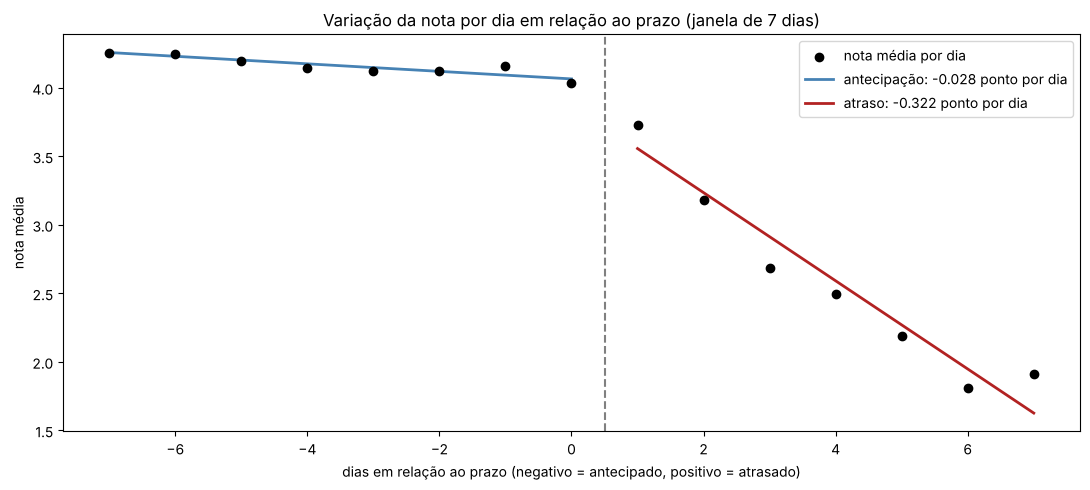

In [22]:
def comparar_inclinacoes(dados, janela, coluna='review_score'):
    """Ajusta uma reta de cada lado do prazo e testa se a inclinação do atraso é maior, em módulo."""
    antecipacao = dados[dados['diferenca_prazo_dias'].between(-janela, 0)]
    atraso = dados[dados['diferenca_prazo_dias'].between(1, janela)]

    reta_antecipacao = st.linregress(antecipacao['diferenca_prazo_dias'], antecipacao[coluna].astype(float))
    reta_atraso = st.linregress(atraso['diferenca_prazo_dias'], atraso[coluna].astype(float))

    z = (abs(reta_atraso.slope) - abs(reta_antecipacao.slope)) / math.sqrt(
        reta_antecipacao.stderr ** 2 + reta_atraso.stderr ** 2)
    p_valor = 1 - st.norm.cdf(z)

    return {
        'janela (dias)': janela,
        'pedidos antecipação': len(antecipacao),
        'pedidos atraso': len(atraso),
        'inclinação antecipação': round(reta_antecipacao.slope, 4),
        'IC 95% antecipação': (round(reta_antecipacao.slope - 1.96 * reta_antecipacao.stderr, 4),
                               round(reta_antecipacao.slope + 1.96 * reta_antecipacao.stderr, 4)),
        'inclinação atraso': round(reta_atraso.slope, 4),
        'IC 95% atraso': (round(reta_atraso.slope - 1.96 * reta_atraso.stderr, 4),
                          round(reta_atraso.slope + 1.96 * reta_atraso.stderr, 4)),
        'razão entre os módulos': round(abs(reta_atraso.slope) / abs(reta_antecipacao.slope), 1),
        'z': round(z, 1),
        'p-valor': p_valor
    }, reta_antecipacao, reta_atraso


JANELA_H3 = 7

print('Nota média (KPI2):')
display(pd.DataFrame([comparar_inclinacoes(base, janela)[0] for janela in [5, JANELA_H3, 10]]).set_index('janela (dias)'))

print('Taxa de avaliação negativa (KPI1):')
display(pd.DataFrame([comparar_inclinacoes(base, janela, 'avaliacao_negativa')[0] for janela in [5, JANELA_H3, 10]]).set_index('janela (dias)'))

# Gráfico da janela principal: médias por dia e retas ajustadas
_, reta_antecipacao, reta_atraso = comparar_inclinacoes(base, JANELA_H3)
medias_por_dia = base[base['diferenca_prazo_dias'].between(-JANELA_H3, JANELA_H3)].groupby('diferenca_prazo_dias')['review_score'].mean()

dias_antecipacao = pd.Series(range(-JANELA_H3, 1))
dias_atraso = pd.Series(range(1, JANELA_H3 + 1))

fig, eixo = plt.subplots(figsize=(11, 5))
eixo.scatter(medias_por_dia.index, medias_por_dia.values, color='black', zorder=3, label='nota média por dia')
eixo.plot(dias_antecipacao, reta_antecipacao.intercept + reta_antecipacao.slope * dias_antecipacao,
          color='steelblue', linewidth=2, label=f'antecipação: {reta_antecipacao.slope:+.3f} ponto por dia')
eixo.plot(dias_atraso, reta_atraso.intercept + reta_atraso.slope * dias_atraso,
          color='firebrick', linewidth=2, label=f'atraso: {reta_atraso.slope:+.3f} ponto por dia')
eixo.axvline(0.5, color='gray', linestyle='--')
eixo.set_title(f'Variação da nota por dia em relação ao prazo (janela de {JANELA_H3} dias)')
eixo.set_xlabel('dias em relação ao prazo (negativo = antecipado, positivo = atrasado)')
eixo.set_ylabel('nota média')
eixo.legend()
plt.tight_layout()
plt.show()

**Leitura dos resultados**

Os p-valores exibidos como 0,0 são menores do que a precisão do cálculo, ou seja, praticamente nulos.

**Na base completa, a assimetria é forte e não depende da janela escolhida.** Na janela principal de 7 dias:

- cada dia de antecipação está associado a um ganho de **0,028 ponto** na nota (IC 95%: 0,020 a 0,035);
- cada dia de atraso está associado a uma perda de **0,322 ponto** (IC 95%: 0,298 a 0,345).

A perda por dia de atraso é cerca de **12 vezes** o ganho por dia de antecipação, e os intervalos de confiança não se sobrepõem. Na taxa de avaliação negativa, cada dia de atraso acrescenta 9,6 pp, contra 0,4 pp por dia de antecipação. Com janelas de 5 e 10 dias, a razão fica entre 10 e 47 vezes, sempre com p-valor praticamente nulo. Na janela de 5 dias, o efeito da antecipação sobre a taxa de avaliação negativa nem chega a ser significativo (o IC inclui o zero).

**Por que esse resultado ainda não basta para confirmar a H3.** A aversão à perda prevê que perdas pesem mais que ganhos equivalentes, mas a magnitude estimada na literatura é bem menor: em Tversky e Kahneman (1992), o coeficiente de aversão à perda é de cerca de 2,25. Uma razão de 12 vezes sugere que algo além da reação psicológica ao atraso está inflando a inclinação. A H2 aponta o candidato: na seção 4.2, vimos que a proporção de respostas antes da entrega sobe de 22% para 77% justamente ao longo da primeira semana de atraso, e que quem responde antes avalia muito pior. Se for isso, a inclinação do lado do atraso mede, em boa parte, a mudança na composição de quem responde, e não o efeito de cada dia de atraso sobre a avaliação. Essa possibilidade é verificada na checagem a seguir.

**Checagem de robustez: assimetria entre os clientes que avaliaram depois da entrega**

Os resultados da H2 indicam que a proporção de avaliações respondidas antes da entrega cresce ao longo da primeira semana de atraso, e que essas avaliações são muito mais negativas. Isso pode inflar a inclinação estimada do lado do atraso. Para isolar a variação da nota associada a cada dia de atraso, repetimos a comparação de inclinações considerando apenas as avaliações respondidas depois da entrega, em que o cliente avalia com o produto em mãos e conhecendo o atraso total.

Nesse recorte, o lado do atraso tem menos pedidos, sobretudo nos últimos dias da janela. O volume por dia é apresentado junto, para que a precisão das estimativas possa ser avaliada.

In [23]:
avaliados_depois_da_entrega = base[~base['avaliacao_antes_da_entrega']]

print('Pedidos com avaliação respondida depois da entrega:', len(avaliados_depois_da_entrega))

print('\nNota média (KPI2):')
display(pd.DataFrame([comparar_inclinacoes(avaliados_depois_da_entrega, janela)[0]
                      for janela in [5, JANELA_H3, 10]]).set_index('janela (dias)'))

print('Taxa de avaliação negativa (KPI1):')
display(pd.DataFrame([comparar_inclinacoes(avaliados_depois_da_entrega, janela, 'avaliacao_negativa')[0]
                      for janela in [5, JANELA_H3, 10]]).set_index('janela (dias)'))

print('Volume e nota média por dia de atraso, entre os avaliados depois da entrega:')
avaliados_depois_da_entrega[avaliados_depois_da_entrega['diferenca_prazo_dias'].between(1, 10)].groupby(
    'diferenca_prazo_dias').agg(
    pedidos=('order_id', 'count'),
    nota_media=('review_score', lambda x: round(x.mean(), 2)),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1))
)

Pedidos com avaliação respondida depois da entrega: 90912

Nota média (KPI2):


,pedidos antecipação,pedidos atraso,inclinação antecipação,IC 95% antecipação,inclinação atraso,IC 95% atraso,razão entre os módulos,z,p-valor
janela (dias),,,,,,,,,
5,10059,1722,-0.0208,"(-0.0348, -0.0068)",-0.0201,"(-0.0713, 0.0312)",1.0,-0.0,0.510396
7,18460,1831,-0.0271,"(-0.0346, -0.0196)",-0.0240,"(-0.0634, 0.0153)",0.9,-0.2,0.559991
10,32441,1871,-0.0251,"(-0.0296, -0.0207)",-0.0170,"(-0.051, 0.0169)",0.7,-0.5,0.678015


Taxa de avaliação negativa (KPI1):


,pedidos antecipação,pedidos atraso,inclinação antecipação,IC 95% antecipação,inclinação atraso,IC 95% atraso,razão entre os módulos,z,p-valor
janela (dias),,,,,,,,,
5,10059,1722,0.0023,"(-0.0013, 0.0059)",0.0060,"(-0.0086, 0.0205)",2.6,0.5,0.316821
7,18460,1831,0.0040,"(0.0021, 0.0059)",0.0057,"(-0.0055, 0.0169)",1.4,0.3,0.384896
10,32441,1871,0.0035,"(0.0024, 0.0047)",0.0037,"(-0.0059, 0.0133)",1.1,0.0,0.484167


Volume e nota média por dia de atraso, entre os avaliados depois da entrega:


,pedidos,nota_media,taxa_avaliacao_negativa
diferenca_prazo_dias,,,
1,798,3.78,18.3
2,383,3.70,18.3
3,254,3.71,20.1
4,171,3.80,18.7
5,116,3.63,21.6
6,60,3.40,28.3
7,49,3.82,14.3
8,18,3.39,16.7
9,13,4.08,15.4


**Leitura dos resultados**

Entre os 90.912 pedidos avaliados depois da entrega, **a assimetria por dia desaparece**. Na janela principal de 7 dias:

- cada dia de antecipação está associado a um ganho de 0,027 ponto na nota (IC 95%: 0,020 a 0,035);
- cada dia de atraso está associado a uma perda de 0,024 ponto (IC 95%: de 0,063 de perda a 0,015 de ganho), estimativa que não se distingue de zero.

A razão entre as inclinações cai de 11,7 para 0,9, e não rejeitamos H₀ em nenhuma das três janelas, nem para a nota nem para a taxa de avaliação negativa (p-valores entre 0,32 e 0,68). A tabela por dia mostra o mesmo: entre quem avaliou com o produto em mãos, a nota fica em torno de 3,7 a 3,8 e a taxa de avaliação negativa em torno de 18% a 20% do primeiro ao quinto dia de atraso, sem a queda progressiva vista na base completa.

**O que isso significa:** a inclinação acentuada observada na base completa é explicada, em grande parte, pela mudança na composição das respostas. Ao longo da primeira semana de atraso, cresce a parcela de clientes que avaliam antes de receber o produto (H2), e são essas avaliações que puxam a média para baixo. Entre quem avalia depois da entrega, um dia a mais de atraso não está associado a uma piora adicional detectável.

**Limitações desta checagem:**

- O lado do atraso tem apenas 1.831 pedidos nesse recorte, e o volume cai para menos de 100 por dia a partir do sexto dia de atraso. Por isso, o intervalo de confiança da inclinação do atraso é largo. Ele exclui a assimetria de 12 vezes da base completa, mas não exclui uma assimetria moderada, da ordem do coeficiente de 2,25 estimado por Tversky e Kahneman (1992). A conclusão correta é que **os dados não permitem detectar** uma assimetria por dia, e não que ela seja inexistente.
- Os clientes atrasados que esperam o produto chegar para responder podem ser, em média, menos insatisfeitos do que os que respondem antes. Esse possível viés de seleção não pode ser controlado com os dados disponíveis.

Se a piora não cresce dia a dia entre quem avalia com o produto em mãos, resta verificar se ela acontece **de uma vez**, no momento em que o prazo é ultrapassado. É o que testamos a seguir.

**O degrau no limite do prazo**

Para verificar se a piora associada ao atraso ocorre no momento em que o prazo é ultrapassado, comparamos pedidos próximos ao limite, todos com avaliação respondida depois da entrega: os entregues entre 3 dias antes e o dia do prazo e os entregues de 1 a 3 dias após o prazo.

Mesmo próximos ao limite, os pedidos atrasados tendem a ter levado mais tempo para chegar do que os pedidos no prazo. Como a seção 4.1 mostrou que a espera, por si só, também está associada à avaliação, a comparação é feita dentro das mesmas faixas de tempo de entrega da H1, com a função `comparar_atraso_por_faixa`. Assim, a diferença em cada faixa se aproxima do efeito de cruzar o limite prometido, com tempo de espera semelhante.

- **H₀:** em cada faixa de tempo de entrega, a taxa de avaliação negativa (e a distribuição das notas) é igual entre os pedidos dos últimos 3 dias no prazo e os dos primeiros 3 dias de atraso.
- **H₁:** a taxa de avaliação negativa (e a distribuição das notas) é diferente entre os dois grupos.

Os testes e o α ajustado por Bonferroni (0,01) são os mesmos da seção 4.1.

In [24]:
DIAS_PROXIMOS_AO_PRAZO = 3

proximos_ao_prazo = avaliados_depois_da_entrega[
    avaliados_depois_da_entrega['diferenca_prazo_dias'].between(-DIAS_PROXIMOS_AO_PRAZO, DIAS_PROXIMOS_AO_PRAZO)]

print(f'Pedidos entre {DIAS_PROXIMOS_AO_PRAZO} dias antes e {DIAS_PROXIMOS_AO_PRAZO} dias depois do prazo '
      f'(avaliados depois da entrega): {len(proximos_ao_prazo)}')
print('Desses, fora do prazo:', proximos_ao_prazo['fora_do_prazo'].sum())
print(f'Alfa ajustado por Bonferroni: {ALFA_BONFERRONI:.3f}')

comparar_atraso_por_faixa(proximos_ao_prazo)

Pedidos entre 3 dias antes e 3 dias depois do prazo (avaliados depois da entrega): 7391
Desses, fora do prazo: 1435
Alfa ajustado por Bonferroni: 0.010


,pedidos no prazo,pedidos fora do prazo,taxa negativa no prazo (%),taxa negativa fora do prazo (%),diferença na taxa negativa (pp),p-valor (teste z),diferença na nota,p-valor (Mann-Whitney),significativo após Bonferroni
faixa,,,,,,,,,
0 a 7 dias,1099,51,4.8,7.8,3.0,0.331264,-0.31,0.016222,False
7 a 14 dias,1208,178,10.3,11.8,1.5,0.556305,-0.13,0.082882,False
14 a 21 dias,1670,266,11.8,17.3,5.5,0.011963,-0.33,0.000003,False
21 a 30 dias,1622,704,14.1,19.6,5.5,0.000740,-0.22,0.000661,True
acima de 30 dias,357,236,21.0,24.6,3.6,0.307928,-0.10,0.471761,False


**Leitura dos resultados**

Entre os 7.391 pedidos avaliados depois da entrega e entregues até 3 dias antes ou depois do prazo (1.435 fora do prazo), os pedidos atrasados têm avaliação pior em todas as faixas de tempo de entrega, mas a diferença é **pequena**: de 1,5 a 5,5 pp a mais de avaliações negativas e de 0,10 a 0,33 ponto a menos na nota. Pelo critério adotado (os dois testes abaixo de 0,01), a diferença é significativa apenas na faixa de 21 a 30 dias (5,5 pp; −0,22 ponto). Na faixa de 14 a 21 dias, a nota é significativamente menor (p < 0,001), mas o teste z da taxa negativa fica no limite (p = 0,012). Nas demais faixas, a diferença não é significativa.

Para comparação, na base completa (seção 4.1) a diferença entre atrasados e não atrasados dentro das mesmas faixas ia de 24 a 53 pp.

**Síntese da H3**

1. **Na base completa**, cada dia de atraso está associado a uma perda de nota cerca de 12 vezes maior do que o ganho de um dia de antecipação.
2. **Essa assimetria desaparece entre quem avalia com o produto em mãos.** Nesse grupo, não há piora progressiva detectável a cada dia de atraso, e a inclinação dos dois lados do prazo é estatisticamente igual.
3. **O cruzamento do prazo tem um efeito pequeno entre quem avalia depois da entrega**, de até 5,5 pp a mais de avaliações negativas, confirmado estatisticamente em apenas uma faixa de tempo de entrega.

**Conclusão sobre a H3:** a hipótese não é sustentada na forma em que foi formulada. A assimetria observada na base completa é explicada principalmente pelo mecanismo da H2: à medida que o atraso cresce, mais clientes respondem à pesquisa sem ter recebido o produto, e essas avaliações são muito mais negativas. Os dados não permitem afirmar que cada dia de atraso pese mais do que cada dia de antecipação na avaliação de quem recebeu o produto. Como o lado do atraso tem pouco volume nesse recorte, uma assimetria moderada, da ordem prevista pela literatura sobre aversão à perda, também não pode ser descartada.

**Implicação para as hipóteses anteriores:** a H1 continua válida como associação na base completa, mas os resultados da H3 qualificam a sua interpretação. Boa parte da piora associada à quebra da promessa se concentra nas avaliações feitas antes da entrega. Essa integração entre H1, H2 e H3 é retomada nas conclusões (seção 5).

### 4.4 H4: reclamações sobre o produto nas avaliações negativas

**Hipótese:** a participação de reclamações sobre o produto é maior nas avaliações negativas de pedidos entregues no prazo do que nas de pedidos atrasados.

Se a insatisfação dos pedidos atrasados se concentra na entrega, a insatisfação dos pedidos no prazo deve ter outra origem, e o produto é a candidata principal. A seção 3.5 já indicava categorias com avaliação negativa acima do que o atraso explicaria.

**Método de classificação.** O universo são as avaliações negativas (nota 1 ou 2) com comentário escrito. Os comentários são convertidos para minúsculas e têm os acentos removidos. Em seguida, cada comentário é marcado como reclamação sobre o **produto** e/ou sobre a **entrega** se contiver ao menos um termo da lista correspondente. Os termos são radicais (por exemplo, "quebrad" identifica quebrado, quebrada e quebrados) e foram definidos a partir da leitura de amostras de comentários da própria base. Um mesmo comentário pode receber as duas marcações.

- **Produto:** defeito, quebra, dano, qualidade, material, acabamento, mau funcionamento, divergência em relação ao anúncio, produto errado, falsificação, validade, incompatibilidade.
- **Entrega:** não recebimento, atraso, demora, prazo, espera, transportadora, rastreio, extravio, entrega parcial.

A classificação por palavras-chave é uma aproximação. Sua precisão é estimada na etapa seguinte, por validação manual de uma amostra aleatória.

In [25]:
TERMOS_PRODUTO = [
    'defeito', 'defeituos', 'quebrad', 'quebrou', 'danificad', 'avariad', 'avaria', 'amassad', 'riscad',
    'arranhad', 'trincad', 'rachad', 'mancha', 'sujo', 'qualidade', 'material', 'fragil', 'mal acabad',
    'acabamento', 'torto', 'nao funciona', 'nao fuciona', 'parou de funcionar', 'sem funcionar', 'nao liga',
    'diferente', 'nao corresponde', 'anuncio', 'anunciad', 'descricao', 'foto', 'imagem', 'original',
    'falsificad', 'falso', 'replica', 'imitacao', 'errad', 'outro modelo', 'veio outro', 'recebi outro',
    'outra cor', 'nao foi o mesmo', 'nao era o', 'tamanho', 'vazad', 'vazando', 'usado', 'validade',
    'faltando peca', 'faltou peca', 'incomplet', 'compativel', 'nao serve', 'nao servi', 'nao deu certo',
    'pessimo produto', 'produto ruim', 'produto horrivel', 'nao gostei do produto'
]

TERMOS_ENTREGA = [
    'nao recebi', 'nao recebo', 'nao chegou', 'ainda nao', 'nao foi entregue', 'nao entreg', 'atras', 'demor',
    'prazo', 'aguardando', 'aguardo', 'esperando', 'esperar', 'espera ', 'transportadora', 'correio', 'rastre',
    'extravi', 'a caminho', 'so recebi', 'recebi apenas', 'recebi so', 'recebi somente', 'veio apenas',
    'entregaram apenas', 'entregaram somente', 'parcial', 'restante', 'metade', 'faltando', 'faltou', 'falta '
]


def normalizar_texto(texto):
    """Converte para minúsculas e remove acentos."""
    texto = unicodedata.normalize('NFKD', texto.lower())
    return texto.encode('ascii', 'ignore').decode('ascii')


def contem_algum_termo(texto, termos):
    return any(termo in texto for termo in termos)


negativas_com_comentario = base[base['avaliacao_negativa'] & base['review_comment_message'].notna()].copy()
negativas_com_comentario['comentario_normalizado'] = negativas_com_comentario['review_comment_message'].apply(normalizar_texto)
negativas_com_comentario['reclamacao_produto'] = negativas_com_comentario['comentario_normalizado'].apply(
    lambda texto: contem_algum_termo(texto, TERMOS_PRODUTO))
negativas_com_comentario['reclamacao_entrega'] = negativas_com_comentario['comentario_normalizado'].apply(
    lambda texto: contem_algum_termo(texto, TERMOS_ENTREGA))

print('Avaliações negativas na base:', base['avaliacao_negativa'].sum())
print(f"Avaliações negativas com comentário: {len(negativas_com_comentario)} "
      f"({len(negativas_com_comentario) / base['avaliacao_negativa'].sum():.1%})")
print('Classificadas como produto:', negativas_com_comentario['reclamacao_produto'].sum())
print('Classificadas como entrega:', negativas_com_comentario['reclamacao_entrega'].sum())
print('Sem nenhuma classificação:',
      (~negativas_com_comentario['reclamacao_produto'] & ~negativas_com_comentario['reclamacao_entrega']).sum())

print('\nCruzamento das duas marcações:')
display(pd.crosstab(negativas_com_comentario['reclamacao_produto'], negativas_com_comentario['reclamacao_entrega'],
                    rownames=['produto'], colnames=['entrega'], margins=True, margins_name='total'))

print('Participação de cada tipo de reclamação, por situação do prazo:')
negativas_com_comentario.groupby('fora_do_prazo').agg(
    avaliacoes=('order_id', 'count'),
    reclamacao_produto=('reclamacao_produto', lambda x: round(x.mean() * 100, 1)),
    reclamacao_entrega=('reclamacao_entrega', lambda x: round(x.mean() * 100, 1))
).rename(index={False: 'no prazo', True: 'fora do prazo'})

Avaliações negativas na base: 12228
Avaliações negativas com comentário: 9194 (75.2%)
Classificadas como produto: 2560
Classificadas como entrega: 4831
Sem nenhuma classificação: 2375

Cruzamento das duas marcações:


entrega,False,True,total
produto,,,
False,2375,4259,6634
True,1988,572,2560
total,4363,4831,9194


Participação de cada tipo de reclamação, por situação do prazo:


,avaliacoes,reclamacao_produto,reclamacao_entrega
fora_do_prazo,,,
no prazo,6449,37.9,41.4
fora do prazo,2745,4.3,78.8


**Leitura dos resultados**

Das 12.228 avaliações negativas da base, 9.194 (75,2%) têm comentário escrito, bem acima da média geral da base (cerca de 41%, seção 2.9). Clientes insatisfeitos tendem a explicar o motivo, o que torna o texto uma fonte rica justamente no grupo que interessa à análise.

**Cobertura da classificação:**

| Marcação | Comentários | % das negativas com comentário |
|---|---|---|
| Só produto | 1.988 | 21,6% |
| Só entrega | 4.259 | 46,3% |
| Produto e entrega | 572 | 6,2% |
| Nenhuma | 2.375 | 25,8% |

Cerca de três em cada quatro comentários receberam ao menos uma marcação. Os 25,8% sem marcação incluem reclamações genéricas ("loja muito ruim"), pedidos de reembolso sem motivo explícito e reclamações sobre atendimento.

**Comparação entre pedidos no prazo e atrasados:**

| Situação | Avaliações | Reclamação sobre produto | Reclamação sobre entrega |
|---|---|---|---|
| No prazo | 6.449 | 37,9% | 41,4% |
| Fora do prazo | 2.745 | 4,3% | 78,8% |

A diferença vai na direção prevista pela H4 e é grande: nas avaliações negativas de pedidos no prazo, a participação de reclamações sobre produto é quase nove vezes maior do que nas de pedidos atrasados. Nos atrasados, quase oito em cada dez comentários falam da entrega, o que é coerente com a H2: a maior parte desses clientes respondeu antes de receber o produto e, portanto, não tinha como avaliá-lo.

Um dado inesperado: **41,4% das avaliações negativas de pedidos no prazo também mencionam a entrega.** Pela leitura das amostras, esses comentários incluem entregas parciais (pedidos com mais de um item em que apenas parte chegou), pedidos que constam como entregues sem terem chegado e reclamações sobre o frete. Esse ponto é retomado na análise complementar de pedidos com mais de um vendedor.

Antes do teste estatístico, a precisão da classificação precisa ser verificada, porque uma comparação baseada em palavras-chave só é confiável se os erros de classificação forem pequenos e semelhantes nos dois grupos.

**Validação manual da classificação**

Para estimar a precisão da classificação por palavras-chave, sorteamos uma amostra aleatória de 100 avaliações negativas com comentário, estratificada por situação do prazo: 50 de pedidos no prazo e 50 de pedidos atrasados. A estratificação permite verificar se a classificação erra mais em um grupo do que no outro, o que poderia distorcer a comparação da H4. A semente aleatória é fixa, para que a amostra seja reproduzível.

A amostra é exportada para um arquivo CSV contendo apenas o identificador e o texto do comentário, sem a classificação automática e sem a situação do prazo, para que a leitura manual não seja influenciada por elas. Cada comentário é classificado manualmente com os mesmos dois critérios:

- **`produto_manual`** = 1 quando o comentário reclama do produto em si (defeito, quebra, qualidade, divergência em relação ao anúncio, produto errado, peça faltando, falsificação, incompatibilidade).
- **`entrega_manual`** = 1 quando o comentário reclama da entrega (não recebimento, atraso, demora, entrega parcial, extravio).

Um comentário pode receber as duas marcações ou nenhuma.

In [26]:
TAMANHO_POR_GRUPO = 50
ARQUIVO_VALIDACAO = '../validacao_h4_amostra.csv'

amostra_validacao = (
    negativas_com_comentario
    .groupby('fora_do_prazo')
    .sample(n=TAMANHO_POR_GRUPO, random_state=42)
    .sample(frac=1, random_state=42)  # embaralha, para que os grupos não fiquem em sequência no arquivo
)

print('Comentários na amostra:', len(amostra_validacao))
print(amostra_validacao['fora_do_prazo'].value_counts().rename(index={False: 'no prazo', True: 'fora do prazo'}))

# O arquivo só é criado se ainda não existir, para não sobrescrever a classificação manual já preenchida
if Path(ARQUIVO_VALIDACAO).exists():
    print(f'Arquivo {ARQUIVO_VALIDACAO} já existe e foi mantido (contém a classificação manual).')
else:
    arquivo_para_leitura = amostra_validacao[['review_comment_message']].copy()
    arquivo_para_leitura['produto_manual'] = ''
    arquivo_para_leitura['entrega_manual'] = ''
    arquivo_para_leitura.index.name = 'id_amostra'
    arquivo_para_leitura.to_csv(ARQUIVO_VALIDACAO, sep=';', encoding='utf-8-sig')
    print('Arquivo criado para preenchimento:', ARQUIVO_VALIDACAO)

Comentários na amostra: 100
fora_do_prazo
fora do prazo    50
no prazo         50
Name: count, dtype: int64
Arquivo ../validacao_h4_amostra.csv já existe e foi mantido (contém a classificação manual).


**Precisão da classificação**

A leitura manual foi feita sem acesso à classificação automática e à situação do prazo. Para garantir consistência, os comentários de entrega parcial (pedidos com mais de um item em que apenas parte chegou) foram classificados como reclamação sobre a entrega, e não sobre o produto, conforme o critério definido acima.

Comparamos a classificação automática com a manual em cada comentário da amostra e calculamos três medidas para cada tipo de reclamação:

- **Acurácia:** proporção de comentários em que a classificação automática coincide com a manual.
- **Precisão:** entre os comentários marcados automaticamente, a proporção que de fato contém aquele tipo de reclamação.
- **Recall:** entre os comentários que de fato contêm aquele tipo de reclamação, a proporção identificada automaticamente.

As medidas são calculadas para a amostra completa e separadamente para pedidos no prazo e atrasados. Se a classificação errar de forma semelhante nos dois grupos, a comparação da H4 se mantém válida, mesmo que os valores absolutos estejam subestimados ou superestimados.

In [27]:
validacao_manual = pd.read_csv(ARQUIVO_VALIDACAO, sep=None, engine='python',
                               encoding='utf-8-sig', index_col='id_amostra')

celulas_vazias = validacao_manual[['produto_manual', 'entrega_manual']].isna().sum().sum()
print('Comentários lidos do arquivo:', len(validacao_manual))
print('Células sem preenchimento:', celulas_vazias)

# Trava: sem classificação manual completa, a validação não tem sentido
if celulas_vazias > 0:
    raise ValueError(f'O arquivo {ARQUIVO_VALIDACAO} tem {celulas_vazias} células sem classificação manual. '
                     'Preencha as colunas produto_manual e entrega_manual antes de continuar.')

comparacao = negativas_com_comentario.loc[
    validacao_manual.index, ['fora_do_prazo', 'reclamacao_produto', 'reclamacao_entrega']
].join(validacao_manual[['produto_manual', 'entrega_manual']].astype(int))


def calcular_metricas(automatica, manual):
    """Compara a classificação automática com a manual."""
    automatica = automatica.astype(bool)
    manual = manual.astype(bool)
    vp = (automatica & manual).sum()
    fp = (automatica & ~manual).sum()
    fn = (~automatica & manual).sum()
    vn = (~automatica & ~manual).sum()
    return {
        'comentários': len(manual),
        'casos na leitura manual': manual.sum(),
        'verdadeiros positivos': vp,
        'falsos positivos': fp,
        'falsos negativos': fn,
        'verdadeiros negativos': vn,
        'acurácia (%)': round((vp + vn) / len(manual) * 100, 1),
        'precisão (%)': round(vp / (vp + fp) * 100, 1) if (vp + fp) > 0 else float('nan'),
        'recall (%)': round(vp / (vp + fn) * 100, 1) if (vp + fn) > 0 else float('nan')
    }


GRUPOS = {
    'total': pd.Series(True, index=comparacao.index),
    'no prazo': ~comparacao['fora_do_prazo'],
    'fora do prazo': comparacao['fora_do_prazo']
}
TIPOS = {
    'produto': ('reclamacao_produto', 'produto_manual'),
    'entrega': ('reclamacao_entrega', 'entrega_manual')
}

linhas = []
for tipo, (coluna_automatica, coluna_manual) in TIPOS.items():
    for grupo, filtro in GRUPOS.items():
        subconjunto = comparacao[filtro]
        linhas.append({'tipo de reclamação': tipo, 'grupo': grupo,
                       **calcular_metricas(subconjunto[coluna_automatica], subconjunto[coluna_manual])})

pd.DataFrame(linhas).set_index(['tipo de reclamação', 'grupo'])

Comentários lidos do arquivo: 100
Células sem preenchimento: 0


comentários  casos na leitura manual  \
tipo de reclamação grupo                                                 
produto            total                  100                       33   
                   no prazo                50                       29   
                   fora do prazo           50                        4   
entrega            total                  100                       64   
                   no prazo                50                       21   
                   fora do prazo           50                       43   

                                  verdadeiros positivos  falsos positivos  \
tipo de reclamação grupo                                                    
produto            total                             16                 1   
                   no prazo                          14                 1   
                   fora do prazo                      2                 0   
entrega            total                             53                 4   
                   no prazo                          16                 2   
                   fora do prazo                     37                 2   

                                  falsos negativos  verdadeiros negativos  \
tipo de reclamação grupo                                                    
produto            total                        17                     66   
                   no prazo                     15                     20   
                   fora do prazo                 2                     46   
entrega            total                        11                     32   
                   no prazo                      5                     27   
                   fora do prazo                 6                      5   

                                  acurácia (%)  precisão (%)  recall (%)  
tipo de reclamação grupo                                                  
produto            total                  82.0          94.1        48.5  
                   no prazo               68.0          93.3        48.3  
                   fora do prazo          96.0         100.0        50.0  
entrega            total                  85.0          93.0        82.8  
                   no prazo               86.0          88.9        76.2  
                   fora do prazo          84.0          94.9        86.0

**Leitura dos resultados**

**Reclamações sobre entrega.** A classificação funciona bem: acurácia de 85%, precisão de 93% e recall de 83%, com desempenho parecido nos dois grupos (acurácia de 86% no prazo e 84% fora do prazo).

**Reclamações sobre produto.** A classificação é **precisa, mas incompleta**:

- **Precisão de 94,1%:** quando as palavras-chave marcam um comentário como reclamação sobre o produto, quase sempre acertam (16 acertos em 17 marcações).
- **Recall de 48,5%:** as palavras-chave encontram apenas cerca de metade das reclamações sobre produto identificadas na leitura manual. Os casos perdidos usam formulações que a lista de termos não cobre, como "a impressão do quadro é péssima", "o tecido não é impermeável", "recebi na cor marrom" ou "foi entregue o produto em 220 V".

**O erro é semelhante nos dois grupos.** O recall é de 48,3% nos pedidos no prazo e de 50,0% nos atrasados, e a precisão fica acima de 93% em ambos. Isso significa que as taxas automáticas subestimam o nível de reclamações sobre produto, mas de forma parecida nos dois grupos, e a comparação entre eles se mantém válida. O valor de 50,0% nos atrasados se baseia em apenas 4 casos e deve ser lido com cautela.

**A acurácia sozinha engana.** A acurácia para produto é de 96% nos atrasados e de 68% nos pedidos no prazo. A diferença não indica que a classificação funcione melhor nos atrasados, e sim que, nesse grupo, quase não há reclamações sobre produto: marcar "não" em quase tudo já garante acerto alto. Por isso, a precisão e o recall são as medidas mais informativas aqui.

**A própria leitura manual confirma a direção da H4.** Na amostra, 29 dos 50 comentários de pedidos no prazo (58%) reclamam do produto, contra 4 dos 50 de pedidos atrasados (8%). Essa diferença não depende das palavras-chave.

**Decisão:** a lista de termos é mantida sem ajustes. Ampliá-la com os casos perdidos nesta amostra melhoraria o recall aparente, mas a validação deixaria de ser independente, porque estaríamos medindo a precisão com os mesmos comentários usados para ajustar o método. O teste da H4 é feito com as duas fontes: a classificação automática da base completa e a leitura manual da amostra.

**Teste estatístico**

- **H₀:** a participação de reclamações sobre o produto é igual nas avaliações negativas de pedidos no prazo e de pedidos atrasados.
- **H₁:** a participação de reclamações sobre o produto é diferente entre os dois grupos.

O teste é feito com duas fontes complementares, com α = 5%:

1. **Classificação automática, base completa:** teste z para duas proporções.
2. **Leitura manual, amostra de validação:** teste exato de Fisher. O teste z não é adequado nesse caso, porque o grupo de pedidos atrasados tem apenas 4 reclamações sobre produto, abaixo do mínimo de 5 casos por célula recomendado para a aproximação normal.

In [28]:
# 1. Classificação automática, base completa
negativas_no_prazo = negativas_com_comentario[~negativas_com_comentario['fora_do_prazo']]
negativas_fora_do_prazo = negativas_com_comentario[negativas_com_comentario['fora_do_prazo']]

z, p_valor_automatico = teste_z_proporcoes(
    negativas_no_prazo['reclamacao_produto'].sum(), len(negativas_no_prazo),
    negativas_fora_do_prazo['reclamacao_produto'].sum(), len(negativas_fora_do_prazo)
)

print('1. Classificação automática (base completa)')
print(f"   No prazo: {negativas_no_prazo['reclamacao_produto'].sum()} de {len(negativas_no_prazo)} "
      f"({negativas_no_prazo['reclamacao_produto'].mean():.1%})")
print(f"   Fora do prazo: {negativas_fora_do_prazo['reclamacao_produto'].sum()} de {len(negativas_fora_do_prazo)} "
      f"({negativas_fora_do_prazo['reclamacao_produto'].mean():.1%})")
print(f"   Diferença: {(negativas_no_prazo['reclamacao_produto'].mean() - negativas_fora_do_prazo['reclamacao_produto'].mean()) * 100:.1f} pp")
print(f'   z = {z:.1f} | p-valor = {p_valor_automatico:.2e}')

# 2. Leitura manual, amostra de validação
manual_no_prazo = comparacao.loc[~comparacao['fora_do_prazo'], 'produto_manual']
manual_fora_do_prazo = comparacao.loc[comparacao['fora_do_prazo'], 'produto_manual']

tabela_contingencia = [
    [manual_no_prazo.sum(), len(manual_no_prazo) - manual_no_prazo.sum()],
    [manual_fora_do_prazo.sum(), len(manual_fora_do_prazo) - manual_fora_do_prazo.sum()]
]
razao_de_chances, p_valor_manual = st.fisher_exact(tabela_contingencia)

print('\n2. Leitura manual (amostra de validação)')
print(f'   No prazo: {manual_no_prazo.sum()} de {len(manual_no_prazo)} ({manual_no_prazo.mean():.1%})')
print(f'   Fora do prazo: {manual_fora_do_prazo.sum()} de {len(manual_fora_do_prazo)} ({manual_fora_do_prazo.mean():.1%})')
print(f'   Diferença: {(manual_no_prazo.mean() - manual_fora_do_prazo.mean()) * 100:.1f} pp')
print(f'   p-valor (Fisher) = {p_valor_manual:.2e}')

1. Classificação automática (base completa)
   No prazo: 2443 de 6449 (37.9%)
   Fora do prazo: 117 de 2745 (4.3%)
   Diferença: 33.6 pp
   z = 32.9 | p-valor = 0.00e+00

2. Leitura manual (amostra de validação)
   No prazo: 29 de 50 (58.0%)
   Fora do prazo: 4 de 50 (8.0%)
   Diferença: 50.0 pp
   p-valor (Fisher) = 1.12e-07


**Leitura dos resultados**

As duas fontes rejeitam H₀ e apontam na mesma direção:

| Fonte | No prazo | Fora do prazo | Diferença | p-valor |
|---|---|---|---|---|
| Classificação automática (9.194 comentários) | 37,9% | 4,3% | 33,6 pp | < 10⁻¹⁶ (teste z) |
| Leitura manual (100 comentários) | 58,0% | 8,0% | 50,0 pp | 1,1 × 10⁻⁷ (Fisher) |

A diferença é menor na classificação automática, o que é coerente com o recall de cerca de 50% medido na validação: as palavras-chave encontram só metade das reclamações sobre produto, então os valores absolutos ficam subestimados. A leitura manual sugere que **mais da metade das avaliações negativas de pedidos no prazo** reclama do produto em si.

**Conclusão sobre a H4:** os dados sustentam a hipótese. Nas avaliações negativas de pedidos entregues no prazo, a participação de reclamações sobre o produto é muito maior do que nas de pedidos atrasados.

**Interpretação.** O resultado complementa a H2. Nos pedidos atrasados, a maior parte dos clientes avaliou antes de receber o produto e, portanto, não tinha como reclamar dele: a insatisfação é sobre a espera. Nos pedidos no prazo, a entrega deixa de ser o problema principal, e a insatisfação passa a vir do que foi recebido. Isso indica que a avaliação negativa tem **duas origens com causas e responsáveis diferentes**: a logística, nos atrasos, e a qualidade e a fidelidade do anúncio, nos pedidos no prazo, este último um ponto que depende dos vendedores da plataforma.

**Limitação:** a classificação automática não captura cerca de metade das reclamações sobre produto. As taxas automáticas devem ser lidas como limite inferior, e não como estimativa do nível real.

### 4.5 Análise complementar: composição do pedido

Na seção 4.4, 41,4% das avaliações negativas de pedidos entregues no prazo mencionaram a entrega, e a leitura manual identificou vários casos de entrega parcial. Em um marketplace, um mesmo pedido pode reunir itens de vendedores diferentes, despachados separadamente. Para verificar se a composição do pedido está associada à avaliação, dividimos os pedidos em três grupos:

1. **1 vendedor, 1 item** (grupo de referência);
2. **1 vendedor, 2 ou mais itens;**
3. **2 ou mais vendedores.**

A comparação principal considera apenas os pedidos entregues no prazo, para que o atraso não interfira no resultado. Cada grupo é comparado ao grupo de referência pelo teste z para duas proporções, com α ajustado por Bonferroni de 0,05 / 2 = 0,025. Também apresentamos a participação de reclamações sobre entrega e sobre produto nos comentários negativos de cada grupo.

In [29]:
GRUPO_REFERENCIA = '1. 1 vendedor, 1 item'

base['composicao_pedido'] = GRUPO_REFERENCIA
base.loc[(base['numero_de_vendedores'] == 1) & (base['numero_de_itens'] > 1), 'composicao_pedido'] = '2. 1 vendedor, 2+ itens'
base.loc[base['numero_de_vendedores'] > 1, 'composicao_pedido'] = '3. 2+ vendedores'

print('Todos os pedidos:')
display(base.groupby('composicao_pedido').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', lambda x: round(x.mean() * 100, 1)),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1)),
    nota_media=('review_score', lambda x: round(x.mean(), 2))
))

pedidos_no_prazo = base[~base['fora_do_prazo']]
print('Apenas pedidos no prazo:')
display(pedidos_no_prazo.groupby('composicao_pedido').agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1)),
    nota_media=('review_score', lambda x: round(x.mean(), 2))
))

negativas_com_comentario['composicao_pedido'] = base.loc[negativas_com_comentario.index, 'composicao_pedido']
print('Tema dos comentários negativos, apenas pedidos no prazo (classificação automática):')
display(negativas_com_comentario[~negativas_com_comentario['fora_do_prazo']].groupby('composicao_pedido').agg(
    comentarios=('order_id', 'count'),
    reclamacao_entrega=('reclamacao_entrega', lambda x: round(x.mean() * 100, 1)),
    reclamacao_produto=('reclamacao_produto', lambda x: round(x.mean() * 100, 1))
))

ALFA_BONFERRONI_COMPOSICAO = ALFA / 2
referencia = pedidos_no_prazo[pedidos_no_prazo['composicao_pedido'] == GRUPO_REFERENCIA]

print(f'Teste z da taxa de avaliação negativa, pedidos no prazo (alfa ajustado: {ALFA_BONFERRONI_COMPOSICAO})')
for grupo in ['2. 1 vendedor, 2+ itens', '3. 2+ vendedores']:
    comparado = pedidos_no_prazo[pedidos_no_prazo['composicao_pedido'] == grupo]
    z, p_valor = teste_z_proporcoes(
        comparado['avaliacao_negativa'].sum(), len(comparado),
        referencia['avaliacao_negativa'].sum(), len(referencia)
    )
    diferenca = (comparado['avaliacao_negativa'].mean() - referencia['avaliacao_negativa'].mean()) * 100
    print(f'   {grupo} vs. referência: diferença de {diferenca:.1f} pp | z = {z:.1f} | p-valor = {p_valor:.2e} | '
          f'significativo: {p_valor < ALFA_BONFERRONI_COMPOSICAO}')

Todos os pedidos:


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media
composicao_pedido,,,,
"1. 1 vendedor, 1 item",86061,6.8,11.3,4.21
"2. 1 vendedor, 2+ itens",8241,5.8,23.6,3.75
3. 2+ vendedores,1258,1.0,47.1,2.86


Apenas pedidos no prazo:


,pedidos,taxa_avaliacao_negativa,nota_media
composicao_pedido,,,
"1. 1 vendedor, 1 item",80174,7.5,4.36
"2. 1 vendedor, 2+ itens",7762,21.0,3.85
3. 2+ vendedores,1246,46.9,2.87


Tema dos comentários negativos, apenas pedidos no prazo (classificação automática):


,comentarios,reclamacao_entrega,reclamacao_produto
composicao_pedido,,,
"1. 1 vendedor, 1 item",4537,32.2,47.1
"2. 1 vendedor, 2+ itens",1417,59.7,18.5
3. 2+ vendedores,495,73.1,8.7


Teste z da taxa de avaliação negativa, pedidos no prazo (alfa ajustado: 0.025)
   2. 1 vendedor, 2+ itens vs. referência: diferença de 13.5 pp | z = 40.1 | p-valor = 0.00e+00 | significativo: True


   3. 2+ vendedores vs. referência: diferença de 39.3 pp | z = 50.4 | p-valor = 0.00e+00 | significativo: True


**Leitura dos resultados**

**A avaliação piora à medida que o pedido fica mais complexo**, mesmo entre os pedidos entregues no prazo:

| Composição do pedido | Pedidos no prazo | Avaliação negativa | Nota média |
|---|---|---|---|
| 1 vendedor, 1 item | 80.174 | 7,5% | 4,36 |
| 1 vendedor, 2+ itens | 7.762 | 21,0% | 3,85 |
| 2+ vendedores | 1.246 | 46,9% | 2,87 |

As duas diferenças em relação ao grupo de referência são significativas (p-valor praticamente nulo, abaixo do α ajustado de 0,025). Um pedido no prazo com mais de um vendedor tem 39,3 pp a mais de avaliações negativas do que um pedido simples, uma taxa próxima à dos pedidos atrasados como um todo. Os pedidos com mais de um item ou mais de um vendedor representam cerca de 10% dos pedidos no prazo, mas concentram cerca de 27% das avaliações negativas desse grupo.

**O tema das reclamações muda com a composição.** Nos pedidos simples no prazo, a reclamação mais frequente é sobre o produto (47,1%, um limite inferior, dado o recall medido na seção 4.4). Nos pedidos com mais de um vendedor, 73,1% dos comentários negativos falam da entrega, embora o pedido conste como entregue no prazo. Isso é coerente com os casos de entrega parcial encontrados na validação manual.

**Um alerta sobre o registro de entrega.** Os pedidos com mais de um vendedor têm apenas 1,0% de atraso registrado, contra 6,8% dos pedidos simples, e, ainda assim, são os mais mal avaliados e os que mais reclamam da entrega. A base registra uma única data de entrega por pedido, mesmo quando os itens são despachados por vendedores diferentes. Uma possibilidade, que não pode ser verificada com os dados disponíveis, é que essa data reflita a chegada de apenas parte dos itens. Se for o caso, a taxa de pedidos fora do prazo (KPI5) subestima o atraso real nos pedidos com mais de um vendedor, e parte das avaliações negativas classificadas como "no prazo" corresponde, na prática, a entregas incompletas.

**Implicação para a H4:** a participação de reclamações sobre produto nas avaliações negativas de pedidos no prazo é ainda maior quando se isolam os pedidos simples, em que entrega parcial não é possível. Nos pedidos com mais de um item ou vendedor, a origem da insatisfação volta a ser predominantemente logística.

## 5. Conclusões e recomendações

### 5.1 Síntese dos resultados

| Hipótese | Resultado | Evidência principal |
|---|---|---|
| **H1.** A quebra da promessa de prazo está associada a uma piora da avaliação maior do que o tempo de espera | Sustentada | Com espera semelhante, pedidos atrasados têm de 24 a 53 pp a mais de avaliações negativas, em faixas que reúnem 99,1% dos atrasos. Esperar mais dentro do prazo acrescenta cerca de 14 pp. O resultado se mantém dentro de São Paulo. |
| **H2.** Entre os atrasados, a avaliação respondida antes da entrega é pior | Sustentada | 70,1% dos atrasados respondem antes de receber o produto. Esses clientes têm de 56 a 61 pp a mais de avaliações negativas do que os que respondem depois, em todas as faixas de atraso. |
| **H3.** Cada dia de atraso pesa mais do que cada dia de antecipação | Não sustentada na forma formulada | A assimetria de 12 vezes da base completa desaparece entre quem avalia depois da entrega. Nesse grupo, o efeito de cruzar o prazo é pequeno (até 5,5 pp) e não há piora progressiva detectável por dia. |
| **H4.** Reclamações sobre o produto pesam mais nas avaliações negativas de pedidos no prazo | Sustentada | 37,9% contra 4,3% na classificação automática e 58% contra 8% na leitura manual. A classificação tem precisão de 94% e recall de 48%, com erro semelhante nos dois grupos. |
| **Complementar.** Composição do pedido | Associação forte | Entre pedidos no prazo, a taxa de avaliação negativa é de 7,5% nos pedidos simples, 21,0% nos pedidos com mais de um item e 46,9% nos pedidos com mais de um vendedor. |

### 5.2 Interpretação integrada

A figura abaixo resume os resultados em um modelo de associações. Cada caixa representa uma variável analisada, e cada seta representa uma associação testada com a avaliação negativa (KPI1). A cor indica o resultado do teste. As setas indicam associação, e não causalidade, e os valores em cada seta resumem o tamanho do efeito encontrado na seção correspondente. Como vêm de comparações diferentes (diferenças em pontos percentuais ou participações), esses valores não são comparáveis entre si como coeficientes de um mesmo modelo.

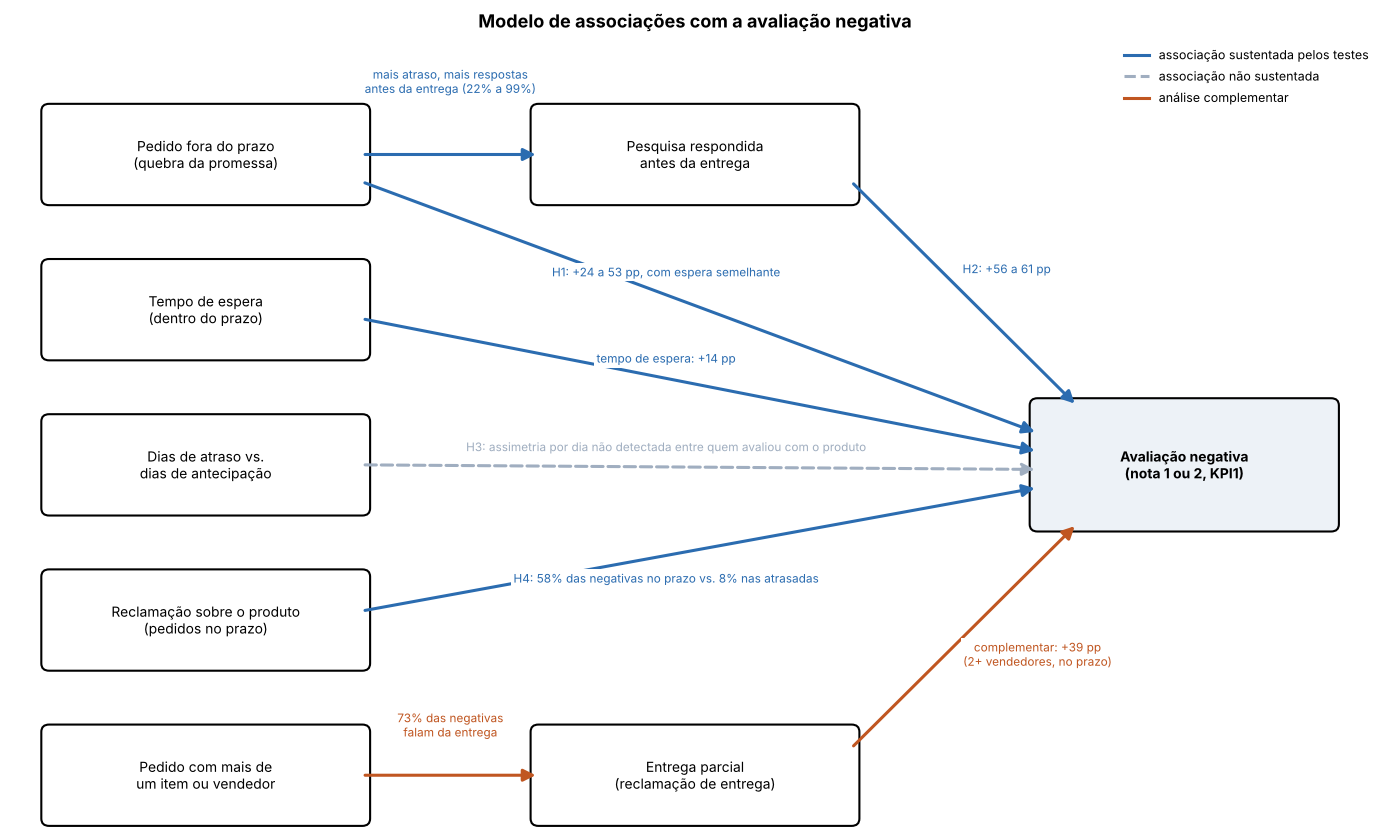

In [30]:
COR_SUSTENTADA = '#2b6cb0'
COR_NAO_SUSTENTADA = '#a0aec0'
COR_COMPLEMENTAR = '#c05621'

fig, eixo = plt.subplots(figsize=(14, 8.5))
eixo.set_xlim(0, 14)
eixo.set_ylim(0, 8.7)
eixo.axis('off')


def desenhar_caixa(x, y, texto, largura=3.2, altura=0.95, cor_fundo='white', negrito=False):
    eixo.add_patch(FancyBboxPatch((x - largura / 2, y - altura / 2), largura, altura,
                                  boxstyle='round,pad=0.08', linewidth=1.5,
                                  edgecolor='black', facecolor=cor_fundo))
    eixo.text(x, y, texto, ha='center', va='center', fontsize=10,
              fontweight='bold' if negrito else 'normal')


def desenhar_seta(origem, destino, rotulo, cor, tracejada=False, posicao=0.5, deslocamento=(0, 0.22)):
    eixo.annotate('', xy=destino, xytext=origem,
                  arrowprops=dict(arrowstyle='-|>', color=cor, linewidth=2.2,
                                  linestyle='--' if tracejada else '-', mutation_scale=18))
    x = origem[0] + (destino[0] - origem[0]) * posicao + deslocamento[0]
    y = origem[1] + (destino[1] - origem[1]) * posicao + deslocamento[1]
    eixo.text(x, y, rotulo, ha='center', va='center', fontsize=8.5, color=cor,
              bbox=dict(facecolor='white', edgecolor='none', pad=1.5))


# Fatores observados no pedido
desenhar_caixa(2.0, 7.4, 'Pedido fora do prazo\n(quebra da promessa)')
desenhar_caixa(2.0, 5.7, 'Tempo de espera\n(dentro do prazo)')
desenhar_caixa(2.0, 4.0, 'Dias de atraso vs.\ndias de antecipação')
desenhar_caixa(2.0, 2.3, 'Reclamação sobre o produto\n(pedidos no prazo)')
desenhar_caixa(2.0, 0.6, 'Pedido com mais de\num item ou vendedor')

# Mecanismos intermediários
desenhar_caixa(7.0, 7.4, 'Pesquisa respondida\nantes da entrega')
desenhar_caixa(7.0, 0.6, 'Entrega parcial\n(reclamação de entrega)')

# Indicador principal
desenhar_caixa(12.0, 4.0, 'Avaliação negativa\n(nota 1 ou 2, KPI1)', largura=3.0, altura=1.3,
               cor_fundo='#edf2f7', negrito=True)

# Associações sustentadas
desenhar_seta((3.6, 7.4), (5.4, 7.4), 'mais atraso, mais respostas\nantes da entrega (22% a 99%)',
              COR_SUSTENTADA, deslocamento=(0, 0.8))
desenhar_seta((8.6, 7.1), (10.9, 4.65), 'H2: +56 a 61 pp', COR_SUSTENTADA, posicao=0.45, deslocamento=(0.55, 0.15))
desenhar_seta((3.6, 7.1), (10.5, 4.35), 'H1: +24 a 53 pp, com espera semelhante', COR_SUSTENTADA,
              posicao=0.45, deslocamento=(0, 0.25))
desenhar_seta((3.6, 5.6), (10.5, 4.15), 'tempo de espera: +14 pp', COR_SUSTENTADA, posicao=0.45)
desenhar_seta((3.6, 2.4), (10.5, 3.75), 'H4: 58% das negativas no prazo vs. 8% nas atrasadas', COR_SUSTENTADA,
              posicao=0.45, deslocamento=(0, -0.25))

# Associação não sustentada
desenhar_seta((3.6, 4.0), (10.5, 3.95), 'H3: assimetria por dia não detectada entre quem avaliou com o produto',
              COR_NAO_SUSTENTADA, tracejada=True, posicao=0.45)

# Análise complementar
desenhar_seta((3.6, 0.6), (5.4, 0.6), '73% das negativas\nfalam da entrega', COR_COMPLEMENTAR, deslocamento=(0, 0.55))
desenhar_seta((8.6, 0.9), (10.9, 3.35), 'complementar: +39 pp\n(2+ vendedores, no prazo)', COR_COMPLEMENTAR,
              deslocamento=(0.75, -0.2))

# Legenda
eixo.plot([], [], color=COR_SUSTENTADA, linewidth=2.2, label='associação sustentada pelos testes')
eixo.plot([], [], color=COR_NAO_SUSTENTADA, linewidth=2.2, linestyle='--', label='associação não sustentada')
eixo.plot([], [], color=COR_COMPLEMENTAR, linewidth=2.2, label='análise complementar')
eixo.legend(loc='upper right', fontsize=9, frameon=False)

eixo.set_title('Modelo de associações com a avaliação negativa', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

A pergunta do projeto era o que explica a avaliação negativa na Olist e onde a empresa pode agir para se diferenciar na experiência do cliente. Os resultados apontam para **três origens distintas de insatisfação**, com responsáveis e soluções diferentes.

**1. O atraso avaliado antes da entrega.** Na base completa, o atraso é o fator mais associado à avaliação negativa (62,4% de avaliações negativas entre os atrasados), e o efeito vai além do tempo de espera, como previa o modelo de desconfirmação de expectativas (Oliver, 1980). A análise das hipóteses H2 e H3, porém, mostra que a maior parte desse efeito se concentra em um grupo específico: os clientes que recebem a pesquisa de satisfação, enviada na data estimada, antes de receber o produto. Eles avaliam uma compra que ainda não chegou, e cerca de 80% dão nota 1 ou 2. Entre os clientes atrasados que avaliam com o produto em mãos, a avaliação é bem menos negativa, e um dia a mais de atraso não está associado a uma piora adicional detectável. Assim, a nota dos pedidos atrasados mede, em grande parte, a frustração de quem ainda está esperando.

**2. O produto, nos pedidos simples entregues no prazo.** Quando a entrega funciona, a insatisfação passa a vir do que foi recebido: defeito, qualidade abaixo do esperado ou divergência em relação ao anúncio. Pela leitura manual, mais da metade das avaliações negativas de pedidos no prazo reclama do produto. Esse problema depende dos vendedores da plataforma e da fidelidade dos anúncios, e não da logística. A seção 3.5 indica categorias em que esse padrão parece mais forte, como `moveis_escritorio`, `cama_mesa_banho` e `informatica_acessorios`.

**3. A entrega fragmentada dos pedidos com mais de um item ou vendedor.** Esses pedidos representam cerca de 10% dos pedidos no prazo, mas concentram cerca de 27% das avaliações negativas desse grupo, e a maior parte de seus comentários negativos fala da entrega. Como a base registra uma única data de entrega por pedido, é possível que parte deles conste como entregue no prazo sem que todos os itens tenham chegado. Nesse caso, o indicador de atraso subestima o problema justamente nos pedidos mais complexos.

**O que os dados mostram e o que apenas sugerem.** Todos os resultados são associações em dados observacionais. A base não permite afirmar que antecipar a pesquisa *cause* avaliações piores, nem que melhorar os anúncios *reduza* as reclamações. Essas relações causais são hipóteses de trabalho, e as recomendações a seguir indicam como testá-las.

### 5.3 Recomendações

**R1. Enviar a pesquisa de satisfação após a confirmação de entrega, e não na data estimada.**
*Base:* H2 e H3. *Origem atacada:* 1.

Esta é a recomendação com maior impacto potencial no indicador e a de menor custo operacional. Deve ser validada por teste A/B antes da adoção:

- **Unidade:** pedidos atrasados, distribuídos aleatoriamente entre dois grupos.
- **Controle:** pesquisa enviada na data estimada, como hoje.
- **Tratamento:** pesquisa enviada somente após a confirmação de entrega.
- **Métrica principal:** taxa de avaliação negativa (KPI1). **Métricas secundárias:** nota média e taxa de resposta à pesquisa.
- **Tamanho da amostra:** para detectar uma redução de 10 pp sobre a taxa observada de 62,4%, com α = 5% e poder de 80%, são necessários cerca de 385 pedidos atrasados por grupo. No volume da base (cerca de 320 pedidos atrasados por mês), isso corresponde a aproximadamente 2,5 meses de teste.

Um cuidado de gestão: essa mudança torna o indicador mais fiel à experiência com o produto, mas não reduz o atraso. A insatisfação de quem espera continua existindo e precisa ser tratada pela R2.

**R2. Comunicar o atraso de forma proativa, antes da data prometida.**
*Base:* H1. *Origem atacada:* 1.

Se a insatisfação vem da quebra da promessa, avisar o cliente com antecedência e oferecer uma nova data é uma forma de reajustar a expectativa antes que ela seja frustrada. A eficácia dessa comunicação não pode ser medida com esta base e também deve ser testada por A/B, com a mesma métrica principal da R1.

**R3. Priorizar a logística nas rotas com mais atraso.**
*Base:* seção 3.4 e H1. *Origem atacada:* 1.

Alagoas, Maranhão e Sergipe têm taxas de atraso entre 15% e 21%, e o Rio de Janeiro combina alto volume (12.172 pedidos) com 12% de atraso. Revisar transportadoras e prazos prometidos nessas rotas é o caminho mais direto para reduzir o problema na origem. Alongar o prazo prometido também reduziria o atraso, mas pode afetar a conversão de vendas, então essa alternativa exige uma análise própria.

**R4. Tratar pedidos com mais de um vendedor como um caso operacional próprio.**
*Base:* seção 4.5. *Origem atacada:* 3.

Três frentes: registrar a data de entrega por item, e não por pedido, para que o indicador de atraso reflita a experiência real; informar ao cliente, no momento da compra, que o pedido chegará em mais de uma entrega; e enviar a pesquisa de satisfação somente após a chegada do último item.

**R5. Monitorar reclamações sobre produto por vendedor e por categoria.**
*Base:* H4 e seção 3.5. *Origem atacada:* 2.

A classificação de comentários desenvolvida neste projeto, com precisão de 94%, pode ser usada como indicador de alerta para vendedores com taxa alta de reclamações sobre produto. Antes do uso operacional, o recall (48%) precisa ser melhorado, ampliando a lista de termos e validando o resultado em uma nova amostra, independente da usada aqui.

### 5.4 Limitações

- **Dados observacionais:** os resultados indicam associação, e não causalidade. As relações causais sugeridas devem ser validadas por experimentos (R1 e R2).
- **Período:** a base cobre compras de janeiro de 2017 a agosto de 2018. A operação da Olist pode ter mudado desde então.
- **Escolha do momento da resposta (H2 e H3):** o cliente decide quando responder à pesquisa. Clientes mais insatisfeitos podem responder mais rápido, o que pode ampliar a diferença observada na H2.
- **Volume no recorte da H3:** entre quem avaliou depois da entrega, o lado do atraso tem pouco volume. Uma assimetria moderada, da ordem prevista pela literatura sobre aversão à perda (Tversky e Kahneman, 1992), não pode ser descartada.
- **Classificação de comentários (H4):** o recall de 48% faz das taxas automáticas um limite inferior. A amostra de validação tem 100 comentários, e a leitura manual foi feita por uma única pessoa.
- **Registro de entrega:** a base tem uma única data de entrega por pedido, o que pode subestimar o atraso em pedidos com mais de um vendedor.
- **Moda:** o volume de pedidos de vestuário na base é pequeno demais para conclusões sobre o segmento, com exceção de `fashion_bolsas_e_acessorios`.

## 6. Entregáveis e fontes

### 6.1 Entregáveis do projeto

- **Notebook de análise:** este arquivo.
- **Dados (`dados/`):** as 7 tabelas da Olist utilizadas na análise, em CSV compactado.
- **Amostra da validação manual (`validacao_h4_amostra.csv`):** 100 comentários classificados manualmente, utilizados na seção 4.4.
- **Dashboard interativo (Tableau Public):** https://public.tableau.com/views/OlistExperinciadoclienteeavaliaonegativa/PainelOlist
- **Apresentação dos resultados (PDF):** arquivo incluído na pasta do projeto.
- **Arquivos do projeto (Google Drive):** https://drive.google.com/drive/folders/1YknyHFHUdyHX_TCUnA9ShqqZyVMuLUpS

### 6.2 Dados

- Olist. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle. Disponível em: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

### 6.3 Referências teóricas

- Kahneman, D.; Tversky, A. (1979). Prospect theory: an analysis of decision under risk. *Econometrica*, 47(2), 263-291.
- Oliver, R. L. (1980). A cognitive model of the antecedents and consequences of satisfaction decisions. *Journal of Marketing Research*, 17(4), 460-469.
- Tversky, A.; Kahneman, D. (1992). Advances in prospect theory: cumulative representation of uncertainty. *Journal of Risk and Uncertainty*, 5(4), 297-323.
- Dunn, O. J. (1961). Multiple comparisons among means. *Journal of the American Statistical Association*, 56(293), 52-64.

### 6.4 Documentação técnica

- pandas: https://pandas.pydata.org/docs/
- SciPy, módulo `scipy.stats` (`mannwhitneyu`, `fisher_exact`, `linregress`, `norm`): https://docs.scipy.org/doc/scipy/reference/stats.html
- Matplotlib: https://matplotlib.org/stable/
- Python, módulo `unicodedata`: https://docs.python.org/3/library/unicodedata.html
- Tableau Public: https://public.tableau.com

### 6.5 Base exportada para o dashboard

Para garantir que o dashboard apresente os mesmos números deste notebook, a base final, já preparada e com o recorte temporal aplicado, é exportada para um arquivo CSV utilizado como fonte de dados no Tableau Public. Cada linha corresponde a um pedido. As variáveis binárias são gravadas como 0 e 1, de modo que a média de cada uma corresponde diretamente à taxa do indicador. As colunas de classificação dos comentários são preenchidas apenas nas avaliações negativas com comentário e ficam vazias nos demais pedidos.

In [31]:
ARQUIVO_DASHBOARD = 'base_dashboard_olist.csv'

REGIOES = {
    'Norte': ['AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO'],
    'Nordeste': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'Centro-Oeste': ['DF', 'GO', 'MS', 'MT'],
    'Sudeste': ['ES', 'MG', 'RJ', 'SP'],
    'Sul': ['PR', 'RS', 'SC']
}
ESTADO_PARA_REGIAO = {estado: regiao for regiao, estados in REGIOES.items() for estado in estados}

base_dashboard = pd.DataFrame({
    'order_id': base['order_id'],
    'data_compra': base['order_purchase_timestamp'].dt.date,
    'mes_compra': base['mes_compra'].dt.to_timestamp().dt.date,
    'estado': base['customer_state'],
    'regiao': base['customer_state'].map(ESTADO_PARA_REGIAO),
    'categoria': base['product_category_name'].fillna('sem categoria'),
    'composicao_pedido': base['composicao_pedido'],
    'nota': base['review_score'],
    'avaliacao_negativa': base['avaliacao_negativa'].astype(int),
    'fora_do_prazo': base['fora_do_prazo'].astype(int),
    'avaliacao_antes_da_entrega': base['avaliacao_antes_da_entrega'].astype(int),
    'tempo_entrega_dias': base['tempo_entrega_dias'].round(2),
    'diferenca_prazo_dias': base['diferenca_prazo_dias'],
    'faixa_tempo_entrega': base['faixa_tempo_entrega'].astype(str),
    'tem_comentario': base['review_comment_message'].notna().astype(int)
})

# Classificação dos comentários: preenchida apenas nas avaliações negativas com comentário
for coluna in ['reclamacao_produto', 'reclamacao_entrega']:
    base_dashboard[coluna] = negativas_com_comentario[coluna].reindex(base_dashboard.index).astype('Int64')

base_dashboard.to_csv(ARQUIVO_DASHBOARD, index=False)

print('Linhas exportadas:', len(base_dashboard))
print('Colunas:', base_dashboard.shape[1])
print('Estados sem região:', base_dashboard['regiao'].isna().sum())
print()
print('Conferência com o notebook:')
print(f"   Taxa de avaliação negativa (KPI1): {base_dashboard['avaliacao_negativa'].mean():.1%}")
print(f"   Nota média (KPI2): {base_dashboard['nota'].mean():.2f}")
print(f"   Taxa fora do prazo (KPI5): {base_dashboard['fora_do_prazo'].mean():.1%}")
print(f"   Reclamação sobre produto entre negativas com comentário (KPI8): {base_dashboard['reclamacao_produto'].mean():.1%}")
print('Arquivo salvo:', ARQUIVO_DASHBOARD)

Linhas exportadas: 95560
Colunas: 17
Estados sem região: 0

Conferência com o notebook:
   Taxa de avaliação negativa (KPI1): 12.8%
   Nota média (KPI2): 4.16
   Taxa fora do prazo (KPI5): 6.7%
   Reclamação sobre produto entre negativas com comentário (KPI8): 27.8%
Arquivo salvo: base_dashboard_olist.csv
